In [1]:
# MỤC ĐÍCH: Nạp các thư viện cần thiết, thiết lập seed và tạo thư mục lưu kết quả.

# ============================================================
# 0.1 Nạp thư viện
# ============================================================
# Đường dẫn file Excel
file_path = "/content/drive/MyDrive/KHDL/online_retail_II.xlsx"
import os, io, json, zipfile, logging, warnings, urllib.request
from itertools import combinations
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.ticker as mt
import matplotlib.dates as md
from matplotlib.colors import LinearSegmentedColormap
from scipy import stats, sparse
from IPython.display import display, Markdown

from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import (silhouette_score, davies_bouldin_score, roc_auc_score, roc_curve,
                             average_precision_score, precision_score, recall_score, f1_score,
                             accuracy_score, confusion_matrix)
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.inspection import permutation_importance

# Không tắt toàn bộ cảnh báo: giữ cảnh báo hữu ích để phát hiện lỗi tương thích/thống kê.
# Chỉ lọc cảnh báo hiển thị không ảnh hưởng kết quả nếu phát sinh từ biểu đồ.
warnings.filterwarnings("ignore", category=UserWarning, module="matplotlib")
logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}" if abs(v) < 10 else f"{v:,.2f}")

RANDOM_STATE = 42                      # cố định seed để kết quả tái lập được
np.random.seed(RANDOM_STATE)
FIG_DIR = Path("figures"); FIG_DIR.mkdir(exist_ok=True)   # thư mục lưu hình cho báo cáo
OUT_DIR = Path("outputs"); OUT_DIR.mkdir(exist_ok=True)   # thư mục lưu bảng kết quả
print("pandas", pd.__version__, "| numpy", np.__version__, "| matplotlib", mpl.__version__)

pandas 2.2.3 | numpy 2.1.3 | matplotlib 3.10.0


In [2]:
# MỤC ĐÍCH: Thiết lập quy chuẩn trình bày biểu đồ, hàm hỗ trợ và nơi lưu các chỉ số chính.

# ============================================================
# 0.2 Phong cách biểu đồ thống nhất cho toàn bộ báo cáo
# Bảng màu phân loại dùng thứ tự cố định, đã kiểm định phân biệt được với người mù màu
# ============================================================
C = {"blue": "#2a78d6", "orange": "#eb6834", "aqua": "#1baf7a", "yellow": "#eda100",
     "magenta": "#e87ba4", "green": "#008300", "violet": "#6250d6", "red": "#e34948"}
INK, INK2, MUTED = "#0b0b0b", "#52514e", "#898781"        # màu chữ: chính / phụ / mờ
GRID, AXIS, NEUTRAL = "#e1e0d9", "#c3c2b7", "#c9c7bf"      # lưới, trục, thanh không nhấn mạnh
SEQ_BLUE = ["#f4f8fd", "#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"]
CMAP_SEQ = LinearSegmentedColormap.from_list("seq_blue", SEQ_BLUE)
CMAP_DIV = LinearSegmentedColormap.from_list("div", ["#c0392b", "#e34948", "#f3b0ac", "#f0efec",
                                                     "#9ec5f4", "#2a78d6", "#184f95"])

# Dùng Inter nếu máy có, nếu không dùng DejaVu Sans (có sẵn trên Colab, hỗ trợ tiếng Việt)
_fonts = {f.name for f in mpl.font_manager.fontManager.ttflist}
FONT = "Inter" if "Inter" in _fonts else "DejaVu Sans"
mpl.rcParams.update({
    "figure.dpi": 100, "savefig.dpi": 200, "savefig.bbox": "tight", "savefig.facecolor": "white",
    "font.family": FONT, "font.size": 10, "axes.titlesize": 12.5, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "axes.titlepad": 22, "axes.labelsize": 10, "axes.labelcolor": INK2,
    "axes.edgecolor": AXIS, "axes.linewidth": 0.8, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.axisbelow": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelcolor": INK2, "ytick.labelcolor": INK2,
    "xtick.major.size": 0, "ytick.major.size": 0, "legend.frameon": False, "legend.fontsize": 9,
    "lines.linewidth": 2, "axes.prop_cycle": mpl.cycler(color=list(C.values())),
})

# Bộ định dạng số trên trục
GBP = mt.FuncFormatter(lambda v, p: f"£{v/1e6:.1f}M" if abs(v) >= 1e6 else (f"£{v/1e3:.0f}K" if abs(v) >= 1e3 else f"£{v:.0f}"))
THOUS = mt.FuncFormatter(lambda v, p: f"{v/1e3:.0f}K" if abs(v) >= 1e3 else f"{v:.0f}")
PCT = mt.PercentFormatter(1)
MONTH_FMT = md.DateFormatter("%m/%Y")


def subtitle(ax, text):
    """Dòng mô tả phụ ngay dưới tiêu đề biểu đồ."""
    ax.text(0, 1.015, text, transform=ax.transAxes, fontsize=9, color=MUTED, va="bottom")


def save_fig(fig, name):
    """Lưu hình (dùng cho báo cáo PDF) rồi hiển thị trong notebook."""
    fig.savefig(FIG_DIR / f"{name}.png")
    plt.show()


def clean_axis(ax, keep="x"):
    """Ẩn lưới theo một chiều để biểu đồ cột gọn hơn."""
    ax.grid(axis="y" if keep == "x" else "x", visible=False)


FACTS = {}   # lưu các con số then chốt, xuất ra JSON cuối notebook để báo cáo trích dẫn chính xác

In [3]:
# MỤC ĐÍCH: Tìm, đọc hai sheet dữ liệu gốc và ghép thành một bảng giao dịch thống nhất.

# ============================================================
# 1.2 Nạp dữ liệu
# Thứ tự ưu tiên: file có sẵn trên máy -> tải từ GitHub của nhóm -> tải bản gốc từ UCI
# ============================================================
GITHUB_RAW = None  # Điền URL raw GitHub thật của nhóm nếu đã công khai dữ liệu; để None sẽ tải bản gốc UCI.
UCI_ZIP = "https://archive.ics.uci.edu/static/public/502/online+retail+ii.zip"
LOCAL_CANDIDATES = [Path("data/online_retail_II.xlsx"), Path("../data/online_retail_II.xlsx"),
                    Path("online_retail_II.xlsx"), Path("/content/online_retail_II.xlsx"), Path("/mnt/data/online_retail_II.xlsx")]


def get_data_file():
    """Trả về đường dẫn file Excel; tự tải về nếu chưa có."""
    for p in LOCAL_CANDIDATES:
        if p.exists():
            return p
    target = Path("online_retail_II.xlsx")
    if GITHUB_RAW:
        try:
            print("Đang tải dữ liệu từ GitHub ...")
            urllib.request.urlretrieve(GITHUB_RAW, target)
            return target
        except Exception as e:
            print("  Không tải được từ GitHub:", e)
    print("Đang tải dữ liệu gốc từ UCI ...")
    with urllib.request.urlopen(UCI_ZIP) as r:
        zf = zipfile.ZipFile(io.BytesIO(r.read()))
    name = [n for n in zf.namelist() if n.endswith(".xlsx")][0]
    target.write_bytes(zf.read(name))
    return target


DATA_FILE = get_data_file()
# Đọc cả 2 sheet; ép Invoice và StockCode thành chuỗi để không mất chữ cái 'C', 'A', biến thể 'A/B/...'
sheets = pd.read_excel(DATA_FILE, sheet_name=None, dtype={"Invoice": str, "StockCode": str})
for name, d in sheets.items():
    d["Sheet"] = name
    print(f"{name:<16} {d.shape[0]:>9,} dòng × {d.shape[1]-1} cột  |  "
          f"{d.InvoiceDate.min():%d/%m/%Y} → {d.InvoiceDate.max():%d/%m/%Y}")
raw = pd.concat(sheets.values(), ignore_index=True)
print(f"\nGộp 2 sheet: {raw.shape[0]:,} dòng")
raw.head()

Đang tải dữ liệu gốc từ UCI ...
Year 2009-2010     525,461 dòng × 8 cột  |  01/12/2009 → 09/12/2010
Year 2010-2011     541,910 dòng × 8 cột  |  01/12/2010 → 09/12/2011

Gộp 2 sheet: 1,067,371 dòng


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,Sheet
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.950,"13,085.00",United Kingdom,Year 2009-2010
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.750,"13,085.00",United Kingdom,Year 2009-2010
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.750,"13,085.00",United Kingdom,Year 2009-2010
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.100,"13,085.00",United Kingdom,Year 2009-2010
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.250,"13,085.00",United Kingdom,Year 2009-2010


In [4]:
# MỤC ĐÍCH: Lập hồ sơ dữ liệu: kiểu dữ liệu, số lượng thiếu và số giá trị phân biệt của từng cột.

# ============================================================
# 1.3 Bảng hồ sơ dữ liệu (data profile) cho từng cột
# ============================================================
COLS = ["Invoice", "StockCode", "Description", "Quantity", "InvoiceDate", "Price", "Customer ID", "Country"]
profile = pd.DataFrame({
    "Kiểu dữ liệu": raw[COLS].dtypes.astype(str),
    "Số giá trị thiếu": raw[COLS].isna().sum(),
    "% thiếu": (raw[COLS].isna().mean() * 100).round(2),
    "Số giá trị khác nhau": raw[COLS].nunique(),
    "Giá trị ví dụ": [str(raw[c].dropna().iloc[0]) for c in COLS],
})
profile.to_csv(OUT_DIR / "data_profile.csv")
FACTS.update(raw_rows=len(raw), raw_missing_customer=int(raw["Customer ID"].isna().sum()),
             raw_missing_desc=int(raw.Description.isna().sum()),
             raw_rows_by_sheet={k: len(v) for k, v in sheets.items()})
profile

,Kiểu dữ liệu,Số giá trị thiếu,% thiếu,Số giá trị khác nhau,Giá trị ví dụ
Invoice,object,0,0.000,53628,489434
StockCode,object,0,0.000,5305,85048
Description,object,4382,0.410,5698,15CM CHRISTMAS GLASS BALL 20 LIGHTS
Quantity,int64,0,0.000,1057,12
InvoiceDate,datetime64[ns],0,0.000,47635,2009-12-01 07:45:00
Price,float64,0,0.000,2807,6.95
Customer ID,float64,243007,22.77,5942,13085.0
Country,object,0,0.000,43,United Kingdom


In [5]:
# MỤC ĐÍCH: Tính thống kê mô tả ban đầu để nhận diện giá trị âm, bằng 0 và cực trị.

# ============================================================
# 1.4 Thống kê mô tả các biến số – phát hiện ngay giá trị âm và cực trị bất thường
# ============================================================
desc_raw = raw[["Quantity", "Price"]].describe(percentiles=[.01, .25, .5, .75, .99]).T
FACTS.update(raw_qty_min=float(raw.Quantity.min()), raw_qty_max=float(raw.Quantity.max()),
             raw_price_min=float(raw.Price.min()), raw_price_max=float(raw.Price.max()),
             raw_neg_qty=int((raw.Quantity <= 0).sum()), raw_nonpos_price=int((raw.Price <= 0).sum()))
desc_raw

,count,mean,std,min,1%,25%,50%,75%,99%,max
Quantity,"1,067,371.00",9.939,172.71,"-80,995.00",-3.000,1.000,3.000,10.00,100.00,"80,995.00"
Price,"1,067,371.00",4.649,123.55,"-53,594.36",0.210,1.250,2.100,4.150,18.00,"38,970.00"


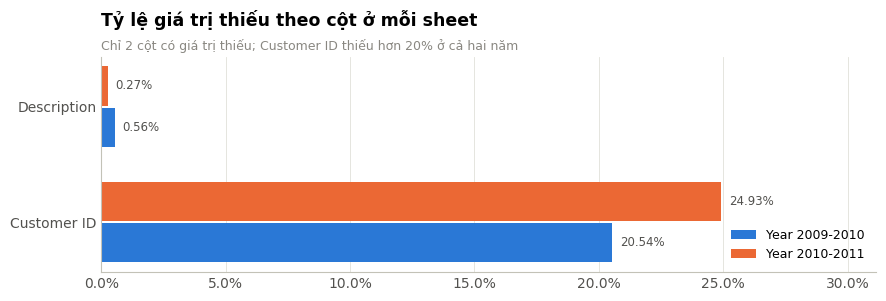

In [6]:
# MỤC ĐÍCH: Tính và trực quan hóa tỷ lệ dữ liệu thiếu theo từng sheet.

# ============================================================
# 1.5 Trực quan hoá tỷ lệ thiếu theo cột và theo sheet
# ============================================================
miss = raw.groupby("Sheet")[COLS].apply(lambda d: d.isna().mean()).T
miss = miss[(miss > 0).any(axis=1)]
fig, ax = plt.subplots(figsize=(10, 2.8))
y = np.arange(len(miss))
for k, (sheet, col) in enumerate(zip(miss.columns, [C["blue"], C["orange"]])):
    ax.barh(y - (k - 0.5) * 0.36, miss[sheet], height=0.34, color=col, label=sheet)
    for yi, v in zip(y, miss[sheet]):
        ax.text(v + 0.003, yi - (k - 0.5) * 0.36, f"{v:.2%}", va="center", fontsize=8.5, color=INK2)
ax.set_yticks(y, miss.index); ax.invert_yaxis()
ax.xaxis.set_major_formatter(PCT)
ax.set_xlim(0, miss.values.max() * 1.25)
ax.legend(loc="lower right")
clean_axis(ax, "x")
ax.set_title("Tỷ lệ giá trị thiếu theo cột ở mỗi sheet")
subtitle(ax, "Chỉ 2 cột có giá trị thiếu; Customer ID thiếu hơn 20% ở cả hai năm")
save_fig(fig, "fig01_missing_values")

In [7]:
# MỤC ĐÍCH: Đối chiếu cấu trúc, khoảng thời gian và mức độ chồng lấn giữa hai sheet.

# ============================================================
# 1.6 Kiểm tra cấu trúc và khoảng thời gian chồng lấn giữa hai sheet
# ============================================================
s1, s2 = sheets["Year 2009-2010"], sheets["Year 2010-2011"]
print("Cùng tên cột:", list(s1.columns) == list(s2.columns),
      "| Cùng kiểu dữ liệu:", (s1.dtypes == s2.dtypes).all())
print(f"Sheet 1 kết thúc: {s1.InvoiceDate.max()} | Sheet 2 bắt đầu: {s2.InvoiceDate.min()}")

overlap_inv = set(s1.Invoice) & set(s2.Invoice)
ov1 = s1[s1.Invoice.isin(overlap_inv)].drop(columns="Sheet")
ov2 = s2[s2.Invoice.isin(overlap_inv)].drop(columns="Sheet")
# So khớp từng dòng: phần chồng lấn có giống hệt nhau không?
same = (ov1.sort_values(COLS).reset_index(drop=True).fillna(-1)
        .equals(ov2.sort_values(COLS).reset_index(drop=True).fillna(-1)))
print(f"Số hoá đơn xuất hiện ở cả 2 sheet: {len(overlap_inv):,}  ({len(ov2):,} dòng mỗi sheet)")
print("Phần chồng lấn giống hệt nhau ở 2 sheet:", same)
FACTS.update(overlap_invoices=len(overlap_inv), overlap_rows=len(ov2),
             overlap_from=str(s2.InvoiceDate.min()), overlap_to=str(s1.InvoiceDate.max()))

Cùng tên cột: True | Cùng kiểu dữ liệu: True
Sheet 1 kết thúc: 2010-12-09 20:01:00 | Sheet 2 bắt đầu: 2010-12-01 08:26:00
Số hoá đơn xuất hiện ở cả 2 sheet: 1,088  (22,523 dòng mỗi sheet)
Phần chồng lấn giống hệt nhau ở 2 sheet: True


In [8]:
# MỤC ĐÍCH: Kiểm tra sự nhất quán của mã hóa sản phẩm và mô tả sản phẩm giữa hai sheet.

# ============================================================
# 1.7 Kiểm tra nhất quán khoá logic: StockCode–Description và Customer–Country
# ============================================================
desc_per_code = raw.dropna(subset=["Description"]).groupby("StockCode").Description.nunique()
country_per_cust = raw.dropna(subset=["Customer ID"]).groupby("Customer ID").Country.nunique()
print(f"Mã hàng có >1 mô tả khác nhau: {(desc_per_code > 1).sum():,} / {len(desc_per_code):,} mã "
      f"({(desc_per_code > 1).mean():.1%})")
print(f"Khách hàng gắn với >1 quốc gia: {(country_per_cust > 1).sum():,} / {len(country_per_cust):,}")
# Ví dụ một mã hàng có nhiều mô tả
ex_code = desc_per_code.sort_values().index[-1]
FACTS.update(codes_multi_desc=int((desc_per_code > 1).sum()), cust_multi_country=int((country_per_cust > 1).sum()))
raw[raw.StockCode == ex_code].Description.value_counts().head(8).to_frame("Số dòng")

Mã hàng có >1 mô tả khác nhau: 1,232 / 4,950 mã (24.9%)
Khách hàng gắn với >1 quốc gia: 13 / 5,942


,Số dòng
Description,
JUMBO BAG OWLS,1372
missing,1
wrongly marked. 23343 in box,1
wrongly coded-23343,1
found,1
Found,1
wrongly marked 23343,1
Marked as 23343,1


In [9]:
# MỤC ĐÍCH: Tổng hợp các chỉ số kiểm tra dữ liệu ban đầu để phục vụ nhận xét giai đoạn 1.

# ============================================================
# 2.1 Khởi tạo nhật ký làm sạch
# ============================================================
clean_log = []


def log_step(name, before, after, note):
    clean_log.append({"Bước": name, "Số dòng trước": before, "Số dòng sau": after,
                      "Số dòng loại": before - after, "Lý do": note})


# ============================================================
# 2.2 Loại phần chồng lấn giữa 2 sheet: giữ bản ở sheet 2009-2010, bỏ bản lặp ở sheet 2010-2011
# ============================================================
df = pd.concat([s1, s2[~s2.Invoice.isin(overlap_inv)]], ignore_index=True)
log_step("Loại chồng lấn giữa 2 sheet", len(raw), len(df), "Hoá đơn 01–09/12/2010 có ở cả 2 sheet")

In [10]:
# MỤC ĐÍCH: Xuất bảng/biểu đồ mô tả các vấn đề chất lượng dữ liệu ban đầu.

# ============================================================
# 2.3 Dữ liệu trùng lặp: minh chứng bằng ví dụ rồi loại bỏ
# ============================================================
dup_mask = df.duplicated(subset=COLS, keep=False)
print(f"Số dòng trùng hoàn toàn (tính cả bản gốc): {dup_mask.sum():,}")
display(df[dup_mask].sort_values(COLS).head(6)[COLS])
n = len(df)
df = df.drop_duplicates(subset=COLS).copy()
log_step("Loại dòng trùng lặp hoàn toàn", n, len(df), "Trùng cả 8 thuộc tính – lỗi ghi nhận kép")

Số dòng trùng hoàn toàn (tính cả bản gốc): 22,813


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
379,489517,21491,SET OF THREE VINTAGE GIFT WRAPS,1,2009-12-01 11:34:00,1.950,"16,329.00",United Kingdom
391,489517,21491,SET OF THREE VINTAGE GIFT WRAPS,1,2009-12-01 11:34:00,1.950,"16,329.00",United Kingdom
365,489517,21821,GLITTER STAR GARLAND WITH BELLS,1,2009-12-01 11:34:00,3.750,"16,329.00",United Kingdom
386,489517,21821,GLITTER STAR GARLAND WITH BELLS,1,2009-12-01 11:34:00,3.750,"16,329.00",United Kingdom
363,489517,21912,VINTAGE SNAKES & LADDERS,1,2009-12-01 11:34:00,3.750,"16,329.00",United Kingdom
371,489517,21912,VINTAGE SNAKES & LADDERS,1,2009-12-01 11:34:00,3.750,"16,329.00",United Kingdom


In [11]:
# MỤC ĐÍCH: Xác định và loại các dòng giao dịch trùng lặp theo bộ thuộc tính giao dịch.

# ============================================================
# 2.4 Sai định dạng (1): mã hoá đơn – phân loại theo tiền tố
# ============================================================
prefix = np.where(df.Invoice.str.match(r"^\d{6}$"), "6 chữ số (bán hàng)", "Tiền tố " + df.Invoice.str[0])
display(pd.crosstab(prefix, df.Quantity > 0).rename(columns={True: "Quantity>0", False: "Quantity≤0"}))
display(df[df.Invoice.str.startswith("A")][COLS])   # 'A' = điều chỉnh nợ xấu
FACTS["raw_cancel_rows"] = int(df.Invoice.str.startswith("C").sum())

Quantity,Quantity≤0,Quantity>0
row_0,,
6 chữ số (bán hàng),3393,1010533
Tiền tố A,0,6
Tiền tố C,19103,1


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
179403,A506401,B,Adjust bad debt,1,2010-04-29 13:36:00,"-53,594.36",NaN,United Kingdom
276274,A516228,B,Adjust bad debt,1,2010-07-19 11:24:00,"-44,031.79",NaN,United Kingdom
403472,A528059,B,Adjust bad debt,1,2010-10-20 12:04:00,"-38,925.87",NaN,United Kingdom
802920,A563185,B,Adjust bad debt,1,2011-08-12 14:50:00,"11,062.06",NaN,United Kingdom
802921,A563186,B,Adjust bad debt,1,2011-08-12 14:51:00,"-11,062.06",NaN,United Kingdom
802922,A563187,B,Adjust bad debt,1,2011-08-12 14:52:00,"-11,062.06",NaN,United Kingdom


In [12]:
# MỤC ĐÍCH: Đo lường số dòng bị ảnh hưởng sau bước xử lý trùng lặp.

# ============================================================
# 2.5 Sai định dạng (2): StockCode không theo chuẩn 5 chữ số -> phí dịch vụ, không phải sản phẩm
# ============================================================
odd = df[~df.StockCode.str.match(r"^\d{5}")]
odd_tbl = (odd.groupby("StockCode").agg(Mô_tả=("Description", lambda s: s.dropna().iloc[0] if s.notna().any() else ""),
                                       Số_dòng=("Invoice", "size"))
           .sort_values("Số_dòng", ascending=False))
odd_tbl.head(20)

,Mô_tả,Số_dòng
StockCode,,
POST,POSTAGE,2086
DOT,DOTCOM POSTAGE,1425
M,Manual,1387
C2,CARRIAGE,277
D,Discount,173
S,SAMPLES,101
BANK CHARGES,Bank Charges,100
ADJUST,Adjustment by john on 26/01/2010 16,67
AMAZONFEE,AMAZON FEE,36


In [13]:
# MỤC ĐÍCH: Kiểm tra các mã hàng không phải sản phẩm bán thông thường trước khi lọc.

# ============================================================
# 2.6 Loại hoá đơn điều chỉnh 'A' và các mã không phải sản phẩm
# DCGS*** là sản phẩm thật (túi quà, đồ trang trí) nên được GIỮ LẠI
# ============================================================
NON_PRODUCT = {"POST", "DOT", "M", "m", "C2", "D", "S", "B", "BANK CHARGES", "ADJUST", "ADJUST2",
               "AMAZONFEE", "PADS", "CRUK", "TEST001", "TEST002", "SP1002"}
is_service = df.StockCode.isin(NON_PRODUCT) | df.StockCode.str.startswith("gift_0001")
FACTS["service_rows"] = int(is_service.sum())

n = len(df)
df = df[~df.Invoice.str.startswith("A")]
log_step("Loại hoá đơn điều chỉnh nợ xấu (A)", n, len(df), "Bút toán kế toán, không phải giao dịch")
n = len(df)
df = df[~df.StockCode.isin(NON_PRODUCT) & ~df.StockCode.str.startswith("gift_0001")]
log_step("Loại mã không phải sản phẩm", n, len(df), "Phí bưu điện, phí ngân hàng, điều chỉnh, voucher, test…")

In [14]:
# MỤC ĐÍCH: Loại các dòng phí, điều chỉnh, voucher và dữ liệu thử theo danh sách đã rà soát.

# ============================================================
# 2.7 Sai định dạng (3): chuẩn hoá văn bản và kiểu dữ liệu
# ============================================================
df["Description"] = df.Description.astype("string").str.strip().str.upper()   # bỏ khoảng trắng thừa, thống nhất chữ hoa
df["Customer ID"] = df["Customer ID"].astype("Int64")                          # float -> số nguyên có hỗ trợ NA
df["Country"] = df.Country.replace({"EIRE": "Ireland", "RSA": "South Africa"})  # thống nhất tên quốc gia
print(sorted(df.Country.unique()))

['Australia', 'Austria', 'Bahrain', 'Belgium', 'Bermuda', 'Brazil', 'Canada', 'Channel Islands', 'Cyprus', 'Czech Republic', 'Denmark', 'European Community', 'Finland', 'France', 'Germany', 'Greece', 'Hong Kong', 'Iceland', 'Ireland', 'Israel', 'Italy', 'Japan', 'Korea', 'Lebanon', 'Lithuania', 'Malta', 'Netherlands', 'Nigeria', 'Norway', 'Poland', 'Portugal', 'Saudi Arabia', 'Singapore', 'South Africa', 'Spain', 'Sweden', 'Switzerland', 'Thailand', 'USA', 'United Arab Emirates', 'United Kingdom', 'Unspecified', 'West Indies']


In [15]:
# MỤC ĐÍCH: Phân tích dữ liệu thiếu và xác định cách xử lý phù hợp cho Customer ID.

# ============================================================
# 2.8 Các dòng thiếu Customer ID có khác biệt hệ thống không? (kiểm tra cơ chế thiếu)
# ============================================================
valid = df[(~df.Invoice.str.startswith("C")) & (df.Quantity > 0) & (df.Price > 0)]
g_id, g_na = valid[valid["Customer ID"].notna()], valid[valid["Customer ID"].isna()]
cmp = pd.DataFrame({
    "Có Customer ID": [g_id.Price.median(), g_id.Quantity.median(), g_id.groupby("Invoice").size().median(),
                       (g_id.Country == "United Kingdom").mean()],
    "Thiếu Customer ID": [g_na.Price.median(), g_na.Quantity.median(), g_na.groupby("Invoice").size().median(),
                          (g_na.Country == "United Kingdom").mean()],
}, index=["Đơn giá trung vị (£)", "Số lượng trung vị / dòng", "Số dòng trung vị / hoá đơn", "Tỷ lệ khách Anh"])
mw = stats.mannwhitneyu(g_id.Price, g_na.Price)
print(f"Mann–Whitney U so sánh đơn giá: p-value = {mw.pvalue:.2e}")
FACTS.update(missing_id_price_med=float(g_na.Price.median()), with_id_price_med=float(g_id.Price.median()),
             missing_id_qty_med=float(g_na.Quantity.median()), with_id_qty_med=float(g_id.Quantity.median()))
cmp

Mann–Whitney U so sánh đơn giá: p-value = 0.00e+00


,Có Customer ID,Thiếu Customer ID
Đơn giá trung vị (£),1.950,3.290
Số lượng trung vị / dòng,6.000,1.000
Số dòng trung vị / hoá đơn,15.00,20.00
Tỷ lệ khách Anh,0.901,0.988


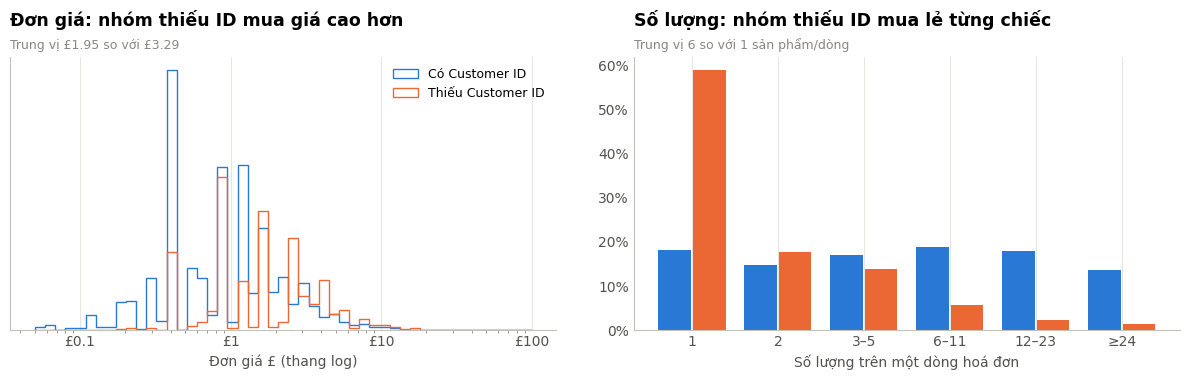

In [16]:
# MỤC ĐÍCH: So sánh phân phối giao dịch giữa nhóm có và không có Customer ID.

# Trực quan: phân phối đơn giá và số lượng của 2 nhóm
fig, axes = plt.subplots(1, 2, figsize=(12, 3.9))
ax = axes[0]
bins = np.logspace(-1.3, 2, 50)
for g, lab, colr in [(g_id, "Có Customer ID", C["blue"]), (g_na, "Thiếu Customer ID", C["orange"])]:
    ax.hist(g.Price.clip(bins[0], bins[-1]), bins=bins, density=True, histtype="step", lw=2, color=colr, label=lab)
ax.set_xscale("log"); ax.set_yticks([]); clean_axis(ax, "x"); ax.set_xlabel("Đơn giá £ (thang log)")
ax.xaxis.set_major_formatter(mt.FuncFormatter(lambda v, p: f"£{v:g}"))
ax.legend(loc="upper right")
ax = axes[1]   # số lượng: nhóm theo khoảng để so sánh tỷ trọng
qb = [0, 1, 2, 5, 11, 23, np.inf]; ql = ["1", "2", "3–5", "6–11", "12–23", "≥24"]
x = np.arange(len(ql))
for k, (g, colr) in enumerate([(g_id, C["blue"]), (g_na, C["orange"])]):
    share = pd.cut(g.Quantity, qb, labels=ql).value_counts(normalize=True).reindex(ql)
    ax.bar(x + (k - 0.5) * 0.4, share.values, width=0.38, color=colr)
ax.set_xticks(x, ql); ax.yaxis.set_major_formatter(PCT); clean_axis(ax); ax.set_xlabel("Số lượng trên một dòng hoá đơn")
axes[0].set_title("Đơn giá: nhóm thiếu ID mua giá cao hơn")
subtitle(axes[0], f"Trung vị £{g_id.Price.median():.2f} so với £{g_na.Price.median():.2f}")
axes[1].set_title("Số lượng: nhóm thiếu ID mua lẻ từng chiếc")
subtitle(axes[1], f"Trung vị {g_id.Quantity.median():.0f} so với {g_na.Quantity.median():.0f} sản phẩm/dòng")
fig.tight_layout(w_pad=3)
save_fig(fig, "fig02_missing_id_profile")

In [17]:
# MỤC ĐÍCH: Tổng hợp bằng chứng quan sát về tình trạng thiếu Customer ID, không khẳng định MNAR khi chưa đủ căn cứ.

# ============================================================
# 2.9 Tách giao dịch huỷ (mã 'C') thành bảng riêng – vẫn dùng để phân tích hành vi huỷ đơn
# ============================================================
n = len(df)
cancels = df[df.Invoice.str.startswith("C")].copy()
df = df[~df.Invoice.str.startswith("C")]
log_step("Tách hoá đơn huỷ (C) sang bảng riêng", n, len(df), "Giữ để phân tích huỷ đơn, không tính vào doanh thu")

# ============================================================
# 2.10 Loại Quantity ≤ 0 hoặc Price ≤ 0 còn sót lại (ghi nhận hàng hỏng, thất lạc, hàng tặng giá 0)
# ============================================================
bad = df[(df.Quantity <= 0) | (df.Price <= 0)]
print("Ví dụ mô tả của các dòng Quantity/Price không hợp lệ:")
print(bad.Description.value_counts(dropna=False).head(8).to_string())
n = len(df)
df = df[(df.Quantity > 0) & (df.Price > 0)].copy()
log_step("Loại Quantity ≤ 0 hoặc Price ≤ 0", n, len(df), "Ghi chú kho (damaged, lost, ?), hàng tặng 0£")

# ============================================================
# 2.11 Điền Description thiếu bằng mô tả phổ biến nhất (mode) của cùng StockCode
# ============================================================
mode_desc = (df.dropna(subset=["Description"]).groupby("StockCode").Description
             .agg(lambda s: s.value_counts().index[0]))
print("\nDescription còn thiếu trước khi điền:", df.Description.isna().sum())
df["Description"] = df.StockCode.map(mode_desc).fillna(df.Description)   # đồng thời thống nhất 1 mã = 1 mô tả
print("Description còn thiếu sau khi điền:", df.Description.isna().sum())

Ví dụ mô tả của các dòng Quantity/Price không hợp lệ:
Description
<NA>                     4240
CHECK                     163
DAMAGED                    99
?                          90
DAMAGES                    88
FOUND                      38
MISSING                    30
SOLD AS SET ON DOTCOM      20

Description còn thiếu trước khi điền: 0
Description còn thiếu sau khi điền: 0


In [18]:
# MỤC ĐÍCH: Tính ngưỡng ngoại lai bằng phương pháp IQR để đánh dấu các quan sát cần điều tra.

# ============================================================
# 2.12 Phát hiện ngoại lai bằng phương pháp IQR (Q3 + 1.5·IQR)
# ============================================================
df["Revenue"] = df.Quantity * df.Price
iqr_rows = []
for col in ["Quantity", "Price", "Revenue"]:
    q1, q3 = df[col].quantile([.25, .75])
    upper = q3 + 1.5 * (q3 - q1)
    iqr_rows.append({"Biến": col, "Q1": q1, "Trung vị": df[col].median(), "Q3": q3, "Ngưỡng trên": upper,
                     "Số dòng vượt": int((df[col] > upper).sum()), "% vượt": (df[col] > upper).mean() * 100,
                     "Max": df[col].max(), "Độ lệch (skew)": df[col].skew()})
iqr_tbl = pd.DataFrame(iqr_rows).set_index("Biến")
iqr_tbl.to_csv(OUT_DIR / "outliers_iqr.csv")
FACTS["iqr"] = iqr_tbl.round(3).to_dict(orient="index")
iqr_tbl

,Q1,Trung vị,Q3,Ngưỡng trên,Số dòng vượt,% vượt,Max,Độ lệch (skew)
Biến,,,,,,,,
Quantity,1.000,4.000,12.00,28.50,53019,5.284,"80,995.00",453.21
Price,1.250,2.100,4.130,8.450,75064,7.481,"1,157.15",41.09
Revenue,4.130,10.08,17.70,38.06,82136,8.186,"168,469.60",661.73


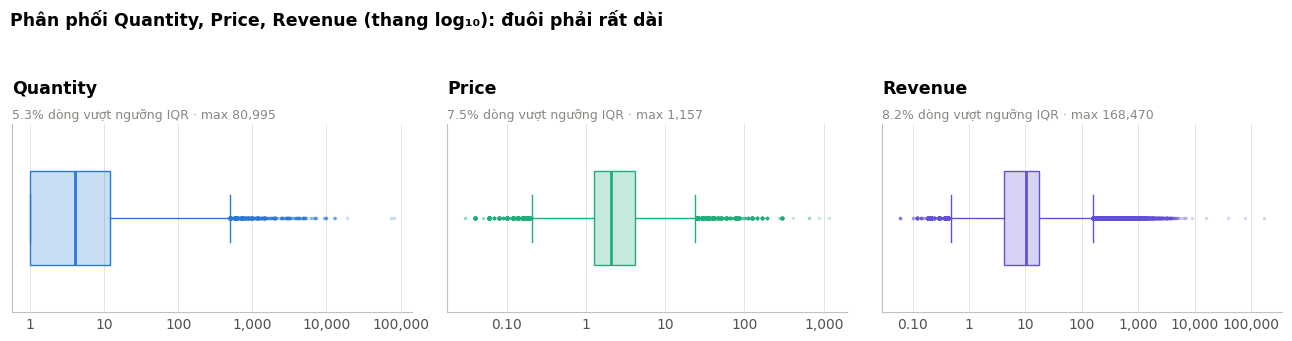

In [19]:
# MỤC ĐÍCH: Trực quan hóa ngoại lai bằng boxplot trên thang log để dễ quan sát phân phối lệch.

# Trực quan: boxplot thang log cho 3 biến
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
for ax, col, colr in zip(axes, ["Quantity", "Price", "Revenue"], [C["blue"], C["aqua"], C["violet"]]):
    ax.boxplot(np.log10(df[col]), vert=False, widths=0.5, patch_artist=True,
               boxprops=dict(facecolor=colr + "40", edgecolor=colr), medianprops=dict(color=colr, lw=2),
               whiskerprops=dict(color=colr), capprops=dict(color=colr),
               flierprops=dict(marker="o", ms=2.5, mfc=colr, mec="none", alpha=0.25))
    ax.set_yticks([]); clean_axis(ax, "x")
    ax.xaxis.set_major_formatter(mt.FuncFormatter(lambda x, p: f"{10**x:,.0f}" if x >= 0 else f"{10**x:.2f}"))
    ax.set_title(col)
    subtitle(ax, f"{iqr_tbl.loc[col, '% vượt']:.1f}% dòng vượt ngưỡng IQR · max {df[col].max():,.0f}")
fig.suptitle("Phân phối Quantity, Price, Revenue (thang log₁₀): đuôi phải rất dài", x=0.01, ha="left",
             fontsize=12.5, fontweight="bold", y=0.99)
fig.tight_layout(rect=(0, 0, 1, 0.93))
save_fig(fig, "fig03_outliers_boxplot")

In [20]:
# MỤC ĐÍCH: Đối chiếu các dòng có giá trị cực lớn với thông tin hóa đơn hủy.

# ============================================================
# 2.13 Điều tra các dòng cực trị: là lỗi nhập liệu hay đơn bán buôn thật?
# ============================================================
top_rev = df.nlargest(8, "Revenue")[["Invoice", "InvoiceDate", "Description", "Quantity", "Price", "Revenue", "Customer ID", "Country"]]
# Đơn có bị huỷ ngay sau đó không? So khớp cùng khách, cùng mã, cùng số lượng âm trong bảng huỷ
key = cancels.assign(Q=-cancels.Quantity).set_index(["Customer ID", "StockCode", "Q"]).index
top_rev["Bị huỷ lại?"] = [(pd.notna(r["Customer ID"]) and (r["Customer ID"], s, r.Quantity) in key)
                          for (_, r), s in zip(top_rev.iterrows(), df.loc[top_rev.index, "StockCode"])]
top_rev

/tmp/ipykernel_1790/889255793.py:9: PerformanceWarning: indexing past lexsort depth may impact performance.
  top_rev["Bị huỷ lại?"] = [(pd.notna(r["Customer ID"]) and (r["Customer ID"], s, r.Quantity) in key)


,Invoice,InvoiceDate,Description,Quantity,Price,Revenue,Customer ID,Country,Bị huỷ lại?
1043359,581483,2011-12-09 09:15:00,"PAPER CRAFT , LITTLE BIRDIE",80995,2.080,"168,469.60",16446,United Kingdom,True
564557,541431,2011-01-18 10:01:00,MEDIUM CERAMIC TOP STORAGE JAR,74215,1.040,"77,183.60",12346,United Kingdom,True
725609,556444,2011-06-10 15:28:00,PICNIC BASKET WICKER SMALL,60,649.50,"38,970.00",15098,United Kingdom,True
432176,530715,2010-11-04 11:36:00,ROTATING SILVER ANGELS T-LIGHT HLDR,9360,1.690,"15,818.40",15838,United Kingdom,True
228042,511465,2010-06-08 12:59:00,PINK PAPER PARASOL,3500,2.550,"8,925.00",18008,United Kingdom,False
851263,567423,2011-09-20 11:05:00,SET OF TEA COFFEE SUGAR TINS PANTRY,1412,5.060,"7,144.72",17450,United Kingdom,False
555649,540815,2011-01-11 12:55:00,FAIRY CAKE FLANNEL ASSORTED COLOUR,3114,2.100,"6,539.40",15749,United Kingdom,True
663484,550461,2011-04-18 13:20:00,FAIRY CAKE FLANNEL ASSORTED COLOUR,3114,2.100,"6,539.40",15749,United Kingdom,True


In [21]:
# MỤC ĐÍCH: Loại các cặp giao dịch có dấu hiệu đặt nhầm và hủy ngay theo điều kiện ghép cụ thể.

# Loại các cặp "đặt nhầm – huỷ ngay" có giá trị cực lớn (cùng khách, cùng mã, cùng số lượng, Revenue > ngưỡng 99.99%)
thr = df.Revenue.quantile(0.9999)
ext = df[df.Revenue > thr]
ext_cancelled = [i for i, r in ext.iterrows()
                 if pd.notna(r["Customer ID"]) and (r["Customer ID"], r.StockCode, r.Quantity) in key]
n = len(df)
df = df.drop(index=ext_cancelled)
log_step("Loại đơn cực trị đã bị huỷ ngay", n, len(df), f"Revenue > £{thr:,.0f} và có hoá đơn huỷ khớp hoàn toàn")
print(f"Ngưỡng 99,99%: £{thr:,.0f} | Số dòng cực trị bị loại: {len(ext_cancelled)}")
FACTS["extreme_cancelled_removed"] = len(ext_cancelled)

Ngưỡng 99,99%: £2,496 | Số dòng cực trị bị loại: 17


/tmp/ipykernel_1790/1416225857.py:7: PerformanceWarning: indexing past lexsort depth may impact performance.
  if pd.notna(r["Customer ID"]) and (r["Customer ID"], r.StockCode, r.Quantity) in key]


In [22]:
# MỤC ĐÍCH: Áp dụng quyết định làm sạch cuối cùng, chỉ loại ngoại lai có căn cứ thay vì xóa máy móc.

# ============================================================
# 2.14 Kỹ thuật đặc trưng (feature engineering) cấp giao dịch
# ============================================================
df["Date"] = df.InvoiceDate.dt.normalize()
df["YearMonth"] = df.InvoiceDate.dt.to_period("M")
df["Year"] = df.InvoiceDate.dt.year
df["Month"] = df.InvoiceDate.dt.month
df["Hour"] = df.InvoiceDate.dt.hour
df["Weekday"] = df.InvoiceDate.dt.dayofweek          # 0 = Thứ 2 ... 6 = Chủ nhật
df["IsUK"] = df.Country.eq("United Kingdom")
df["HasCustomer"] = df["Customer ID"].notna()
cancels["YearMonth"] = cancels.InvoiceDate.dt.to_period("M")
cancels["Revenue"] = cancels.Quantity * cancels.Price
cancels["IsUK"] = cancels.Country.eq("United Kingdom")
sales = df.reset_index(drop=True)
customers_tx = sales[sales.HasCustomer].copy()                # tập con có ID cho phân tích khách hàng

log_df = pd.DataFrame(clean_log)
log_df.to_csv(OUT_DIR / "cleaning_log.csv", index=False)
FACTS.update(clean_rows=len(sales), clean_revenue=float(sales.Revenue.sum()), cancel_rows=len(cancels),
             clean_rows_with_id=int(sales.HasCustomer.sum()))
log_df

,Bước,Số dòng trước,Số dòng sau,Số dòng loại,Lý do
0,Loại chồng lấn giữa 2 sheet,1067371,1044848,22523,Hoá đơn 01–09/12/2010 có ở cả 2 sheet
1,Loại dòng trùng lặp hoàn toàn,1044848,1033036,11812,Trùng cả 8 thuộc tính – lỗi ghi nhận kép
2,Loại hoá đơn điều chỉnh nợ xấu (A),1033036,1033030,6,"Bút toán kế toán, không phải giao dịch"
3,Loại mã không phải sản phẩm,1033030,1027215,5815,"Phí bưu điện, phí ngân hàng, điều chỉnh, vouch..."
4,Tách hoá đơn huỷ (C) sang bảng riêng,1027215,1009301,17914,"Giữ để phân tích huỷ đơn, không tính vào doanh..."
5,Loại Quantity ≤ 0 hoặc Price ≤ 0,1009301,1003338,5963,"Ghi chú kho (damaged, lost, ?), hàng tặng 0£"
6,Loại đơn cực trị đã bị huỷ ngay,1003338,1003321,17,"Revenue > £2,496 và có hoá đơn huỷ khớp hoàn toàn"


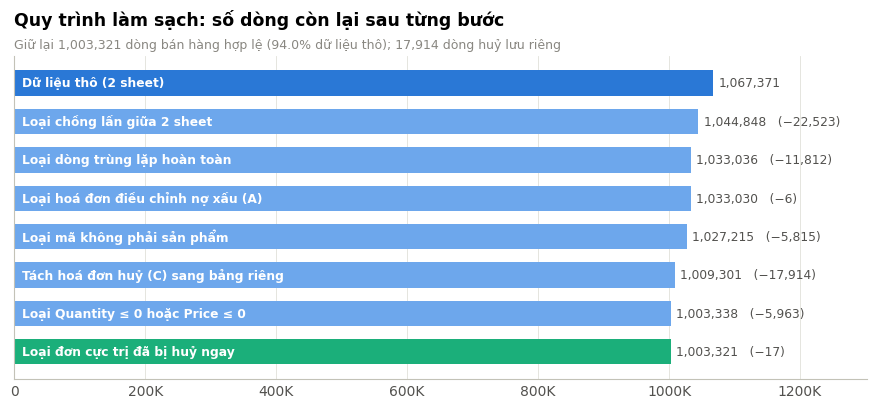

In [23]:
# MỤC ĐÍCH: Trực quan hóa số lượng dòng dữ liệu còn lại sau từng bước làm sạch.

# Trực quan: số dòng còn lại sau từng bước làm sạch
labels = ["Dữ liệu thô (2 sheet)"] + list(log_df["Bước"])
vals = [log_df["Số dòng trước"].iloc[0]] + list(log_df["Số dòng sau"])
fig, ax = plt.subplots(figsize=(11, 4.2))
y = np.arange(len(vals))[::-1]
ax.barh(y, vals, color=[C["blue"]] + ["#6da7ec"] * (len(vals) - 2) + [C["aqua"]], height=0.66)
for yi, v, lab, i in zip(y, vals, labels, range(len(vals))):
    ax.text(12000, yi, lab, va="center", fontsize=8.8, color="white", fontweight="bold")
    removed = "" if i == 0 else f"   (−{vals[i-1]-v:,})"
    ax.text(v + 8000, yi, f"{v:,}{removed}", va="center", fontsize=8.8, color=INK2)
ax.set_yticks([]); ax.set_xlim(0, max(vals) * 1.22); ax.xaxis.set_major_formatter(THOUS); clean_axis(ax, "x")
ax.set_title("Quy trình làm sạch: số dòng còn lại sau từng bước")
subtitle(ax, f"Giữ lại {vals[-1]:,} dòng bán hàng hợp lệ ({vals[-1]/vals[0]:.1%} dữ liệu thô); {len(cancels):,} dòng huỷ lưu riêng")
save_fig(fig, "fig04_cleaning_funnel")

In [24]:
# MỤC ĐÍCH: Chuẩn bị các biến phục vụ phân tích, giải trình biến đổi log, mã hóa và chuẩn hóa.

# ============================================================
# 2.15 Bảng đặc trưng cấp khách hàng (RFM + hành vi) – dùng cho tương quan, phân cụm
# Mốc tham chiếu: 1 ngày sau giao dịch cuối cùng trong dữ liệu
# ============================================================
SNAPSHOT = sales.InvoiceDate.max().normalize() + pd.Timedelta(days=1)


def customer_features(tx, snapshot, cancels_tx=None):
    """Tính đặc trưng cấp khách hàng từ các giao dịch trước thời điểm snapshot."""
    tx = tx[tx.InvoiceDate < snapshot]
    inv = tx.groupby(["Customer ID", "Invoice"]).agg(d=("InvoiceDate", "max"), rev=("Revenue", "sum"),
                                                       items=("StockCode", "nunique")).reset_index()
    g = inv.groupby("Customer ID")
    f = pd.DataFrame({
        "Recency": (snapshot - g.d.max()).dt.days,                 # số ngày từ lần mua cuối
        "Frequency": g.Invoice.nunique(),                          # số hoá đơn
        "Monetary": g.rev.sum(),                                   # tổng chi tiêu
        "Tenure": (snapshot - g.d.min()).dt.days,                  # số ngày từ lần mua đầu
        "AvgOrderValue": g.rev.mean(),                             # giá trị TB một hoá đơn
        "AvgItemsPerOrder": g["items"].mean(),                     # số mặt hàng TB một hoá đơn
    })
    f["UniqueProducts"] = tx.groupby("Customer ID").StockCode.nunique()
    f["ActiveMonths"] = tx.groupby("Customer ID").YearMonth.nunique()
    # Khoảng cách trung bình giữa các lần mua (khách chỉ mua 1 lần -> dùng Tenure)
    gaps = inv.sort_values("d").groupby("Customer ID").d.apply(lambda s: s.diff().dt.days.mean())
    f["AvgDaysBetween"] = gaps.fillna(f.Tenure)
    if cancels_tx is not None:
        c = cancels_tx[cancels_tx.InvoiceDate < snapshot].groupby("Customer ID").Invoice.nunique()
        f["CancelRate"] = (c.reindex(f.index).fillna(0) / (f.Frequency + c.reindex(f.index).fillna(0)))
    country = tx.groupby("Customer ID").Country.agg(lambda s: s.value_counts().index[0])
    f["Country"] = country
    return f


cust = customer_features(customers_tx, SNAPSHOT, cancels.dropna(subset=["Customer ID"]))
FACTS["n_customers"] = len(cust)
cust.describe().T

,count,mean,std,min,25%,50%,75%,max
Recency,"5,852.00",199.80,208.54,0.000,25.00,95.00,379.00,738.00
Frequency,"5,852.00",6.252,12.75,1.000,1.000,3.000,7.000,373.00
Monetary,"5,852.00","2,855.96","14,056.35",2.900,339.24,855.22,"2,236.66","580,987.04"
Tenure,"5,852.00",473.54,223.20,0.000,311.00,529.00,666.00,738.00
AvgOrderValue,"5,852.00",360.94,443.35,2.900,176.06,277.53,409.95,"11,880.84"
AvgItemsPerOrder,"5,852.00",21.27,18.27,1.000,9.800,17.00,27.00,297.88
UniqueProducts,"5,852.00",82.19,116.49,1.000,19.00,45.00,103.00,"2,546.00"
ActiveMonths,"5,852.00",4.358,4.493,1.000,1.000,3.000,6.000,25.00
AvgDaysBetween,"5,852.00",171.70,183.32,0.000,45.17,90.60,234.67,738.00
CancelRate,"5,852.00",0.111,0.161,0.000,0.000,0.000,0.200,0.800


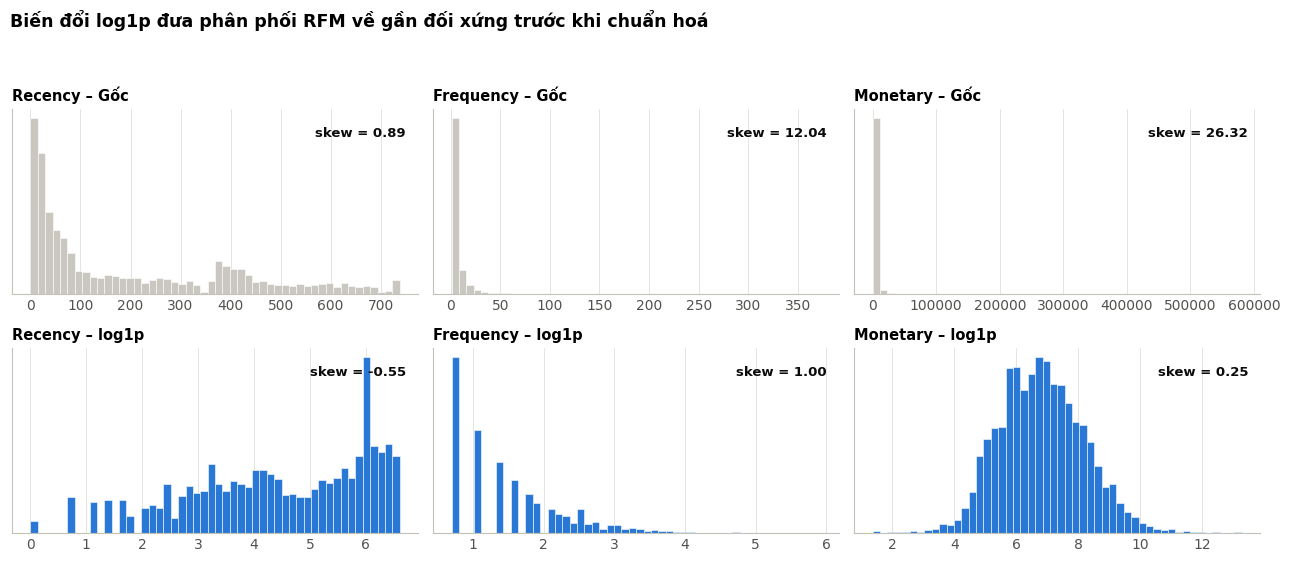

In [25]:
# MỤC ĐÍCH: Minh họa độ lệch của biến trước và sau biến đổi log1p.

# Minh chứng cho lựa chọn log1p: độ lệch trước và sau biến đổi
fig, axes = plt.subplots(2, 3, figsize=(13, 5.6))
for j, col in enumerate(["Recency", "Frequency", "Monetary"]):
    for i, (vals_, lab, colr) in enumerate([(cust[col], "Gốc", NEUTRAL), (np.log1p(cust[col]), "log1p", C["blue"])]):
        ax = axes[i, j]
        ax.hist(vals_, bins=50, color=colr, edgecolor="white", linewidth=0.4)
        ax.set_yticks([]); clean_axis(ax, "x")
        ax.set_title(f"{col} – {lab}", fontsize=10.5, pad=6)
        ax.text(0.97, 0.85, f"skew = {stats.skew(vals_):.2f}", transform=ax.transAxes, ha="right",
                fontsize=9.5, color=INK, fontweight="bold")
fig.suptitle("Biến đổi log1p đưa phân phối RFM về gần đối xứng trước khi chuẩn hoá", x=0.01, ha="left",
             fontsize=12.5, fontweight="bold", y=0.995)
fig.tight_layout(rect=(0, 0, 1, 0.95))
save_fig(fig, "fig05_log_transform")
FACTS["skew_before"] = {c: float(stats.skew(cust[c])) for c in ["Recency", "Frequency", "Monetary"]}
FACTS["skew_after"] = {c: float(stats.skew(np.log1p(cust[c]))) for c in ["Recency", "Frequency", "Monetary"]}

In [26]:
# MỤC ĐÍCH: Tính các chỉ số tổng quan về doanh thu và hoạt động giao dịch.

# ============================================================
# 3.1 Các chỉ số kinh doanh tổng quan (KPI)
# ============================================================
inv_tbl = sales.groupby("Invoice").agg(rev=("Revenue", "sum"), items=("StockCode", "nunique"),
                                       country=("Country", "first"), cust=("Customer ID", "first"),
                                       date=("InvoiceDate", "first"))
kpi = {
    "Tổng doanh thu (£)": sales.Revenue.sum(),
    "Số hoá đơn": sales.Invoice.nunique(),
    "Số khách hàng có ID": sales["Customer ID"].nunique(),
    "Số sản phẩm": sales.StockCode.nunique(),
    "Số quốc gia": sales.Country.nunique(),
    "Giá trị TB / hoá đơn (£)": inv_tbl.rev.mean(),
    "Giá trị trung vị / hoá đơn (£)": inv_tbl.rev.median(),
    "Số mặt hàng trung vị / hoá đơn": inv_tbl["items"].median(),
    "Tỷ trọng doanh thu từ khách không có ID": sales.loc[~sales.HasCustomer, "Revenue"].sum() / sales.Revenue.sum(),
    "Tỷ trọng doanh thu từ Vương quốc Anh": sales.loc[sales.IsUK, "Revenue"].sum() / sales.Revenue.sum(),
}
FACTS["kpi"] = {k: float(v) for k, v in kpi.items()}
pd.Series(kpi).to_frame("Giá trị")

,Giá trị
Tổng doanh thu (£),"19,288,350.31"
Số hoá đơn,"39,511.00"
Số khách hàng có ID,"5,852.00"
Số sản phẩm,"4,893.00"
Số quốc gia,43.00
Giá trị TB / hoá đơn (£),488.18
Giá trị trung vị / hoá đơn (£),301.20
Số mặt hàng trung vị / hoá đơn,15.00
Tỷ trọng doanh thu từ khách không có ID,0.134
Tỷ trọng doanh thu từ Vương quốc Anh,0.853


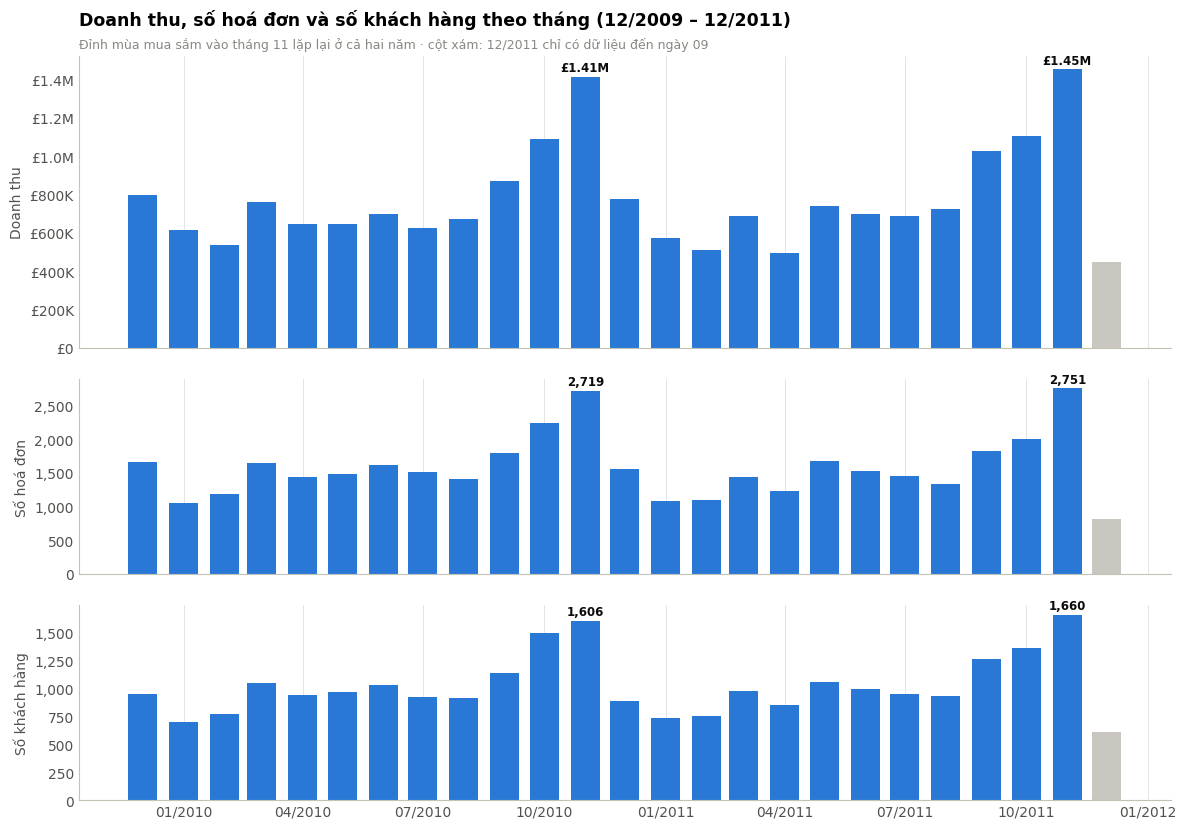

Tháng cao nhất: 11/2011 (£1,452,116) | thấp nhất: 04/2011
Doanh thu T1–T11: 2010 = £8,570,168 | 2011 = £8,698,622 | tăng trưởng +1.5%
T9–T11 chiếm 36.9% doanh thu của 24 tháng đầy đủ


In [27]:
# MỤC ĐÍCH: Tổng hợp doanh thu theo thời gian và phân tích xu hướng theo tháng.

# ============================================================
# 3.2 Xu hướng theo tháng: doanh thu, số hoá đơn, số khách hàng (3 biểu đồ nhỏ chung trục thời gian)
# ============================================================
monthly = sales.groupby("YearMonth").agg(revenue=("Revenue", "sum"), invoices=("Invoice", "nunique"),
                                          customers=("Customer ID", "nunique"))
monthly.index = monthly.index.to_timestamp()
monthly.to_csv(OUT_DIR / "monthly_kpis.csv")
full = monthly.iloc[:-1]   # 12/2011 chỉ có 9 ngày -> không dùng khi so sánh

fig, axes = plt.subplots(3, 1, figsize=(12, 8.4), sharex=True, gridspec_kw={"height_ratios": [1.5, 1, 1]})
for ax, (col, lab, fmt) in zip(axes, [("revenue", "Doanh thu", GBP), ("invoices", "Số hoá đơn", mt.StrMethodFormatter("{x:,.0f}")),
                                      ("customers", "Số khách hàng", mt.StrMethodFormatter("{x:,.0f}"))]):
    ax.bar(monthly.index, monthly[col], width=22, color=[C["blue"]] * (len(monthly) - 1) + [NEUTRAL])
    ax.yaxis.set_major_formatter(fmt); ax.set_ylabel(lab); clean_axis(ax)
    for yr in (2010, 2011):   # ghi giá trị đỉnh mỗi năm
        s = full[full.index.year == yr][col]
        t = s.idxmax()
        ax.annotate(f"£{s.max()/1e6:.2f}M" if col == "revenue" else f"{s.max():,.0f}", (t, s.max()),
                    xytext=(0, 4), textcoords="offset points", ha="center", fontsize=8.5, fontweight="bold", color=INK)
axes[-1].xaxis.set_major_formatter(MONTH_FMT)
axes[0].set_title("Doanh thu, số hoá đơn và số khách hàng theo tháng (12/2009 – 12/2011)")
subtitle(axes[0], "Đỉnh mùa mua sắm vào tháng 11 lặp lại ở cả hai năm · cột xám: 12/2011 chỉ có dữ liệu đến ngày 09")
fig.tight_layout()
save_fig(fig, "fig06_monthly_trend")

r10, r11 = full.loc["2010-01":"2010-11", "revenue"].sum(), full.loc["2011-01":"2011-11", "revenue"].sum()
FACTS.update(best_month=full.revenue.idxmax().strftime("%m/%Y"), best_month_rev=float(full.revenue.max()),
             worst_month=full.revenue.idxmin().strftime("%m/%Y"), worst_month_rev=float(full.revenue.min()),
             rev_jan_nov_2010=float(r10), rev_jan_nov_2011=float(r11), yoy_growth=float(r11 / r10 - 1),
             share_sep_nov=float(full[full.index.month.isin([9, 10, 11])].revenue.sum() / full.revenue.sum()),
             nov2010_vs_feb2010=float(full.loc["2010-11", "revenue"].iloc[0] / full.loc["2010-02", "revenue"].iloc[0]))
print(f"Tháng cao nhất: {FACTS['best_month']} (£{FACTS['best_month_rev']:,.0f}) | thấp nhất: {FACTS['worst_month']}")
print(f"Doanh thu T1–T11: 2010 = £{r10:,.0f} | 2011 = £{r11:,.0f} | tăng trưởng {r11/r10-1:+.1%}")
print(f"T9–T11 chiếm {FACTS['share_sep_nov']:.1%} doanh thu của 24 tháng đầy đủ")

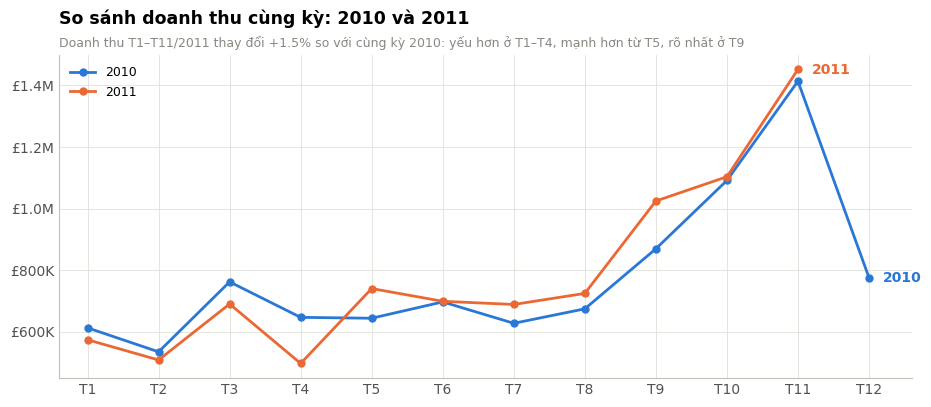

In [28]:
# MỤC ĐÍCH: Phân tích biến động doanh thu theo tháng/năm và các chỉ số tăng trưởng.

# ============================================================
# 3.3 So sánh cùng kỳ 2010 – 2011 theo tháng
# ============================================================
fig, ax = plt.subplots(figsize=(11, 4.2))
for yr, colr in [(2010, C["blue"]), (2011, C["orange"])]:
    s = full[full.index.year == yr]
    ax.plot(s.index.month, s.revenue, marker="o", ms=5, color=colr, label=str(yr))
    ax.text(s.index.month[-1] + 0.2, s.revenue.iloc[-1], str(yr), color=colr, va="center", fontweight="bold")
ax.set_xticks(range(1, 13), [f"T{i}" for i in range(1, 13)]); ax.set_xlim(0.6, 12.6)
ax.yaxis.set_major_formatter(GBP); ax.legend(loc="upper left")
ax.set_title("So sánh doanh thu cùng kỳ: 2010 và 2011")
subtitle(ax, f"Doanh thu T1–T11/2011 thay đổi {FACTS['yoy_growth']:+.1%} so với cùng kỳ 2010: yếu hơn ở T1–T4, mạnh hơn từ T5, rõ nhất ở T9")
save_fig(fig, "fig07_yoy")

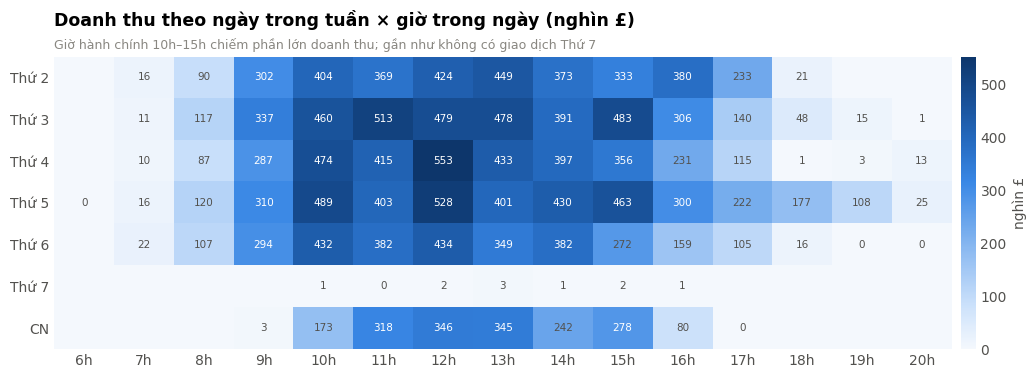

Doanh thu 10h–15h: 75.0% | giờ cao điểm: 12h | số hoá đơn Thứ 7: 30


In [29]:
# MỤC ĐÍCH: Tạo chuỗi thời gian ngày đầy đủ, bao gồm ngày không phát sinh giao dịch với doanh thu bằng 0.

# ============================================================
# 3.4 Nhịp mua hàng trong tuần và trong ngày (heatmap)
# ============================================================
DAYS = ["Thứ 2", "Thứ 3", "Thứ 4", "Thứ 5", "Thứ 6", "Thứ 7", "CN"]
pv = sales.pivot_table(index="Weekday", columns="Hour", values="Revenue", aggfunc="sum").reindex(range(7)).fillna(0)
pv = pv.loc[:, pv.sum() > 0] / 1e3
fig, ax = plt.subplots(figsize=(12, 3.8))
im = ax.imshow(pv.values, aspect="auto", cmap=CMAP_SEQ)
for i in range(pv.shape[0]):
    for j in range(pv.shape[1]):
        v = pv.values[i, j]
        if v > 0:
            ax.text(j, i, f"{v:,.0f}", ha="center", va="center", fontsize=7.5,
                    color="white" if v > pv.values.max() * 0.5 else INK2)
ax.set_xticks(range(pv.shape[1]), [f"{h}h" for h in pv.columns]); ax.set_yticks(range(7), DAYS)
ax.grid(False); [s.set_visible(False) for s in ax.spines.values()]
cb = fig.colorbar(im, ax=ax, fraction=0.025, pad=0.01); cb.outline.set_visible(False)
cb.set_label("nghìn £", color=INK2)
ax.set_title("Doanh thu theo ngày trong tuần × giờ trong ngày (nghìn £)")
subtitle(ax, "Giờ hành chính 10h–15h chiếm phần lớn doanh thu; gần như không có giao dịch Thứ 7")
save_fig(fig, "fig08_weekday_hour")
hour_share = sales.groupby("Hour").Revenue.sum() / sales.Revenue.sum()
FACTS.update(share_10_15=float(hour_share.loc[10:15].sum()), peak_hour=int(hour_share.idxmax()),
             saturday_invoices=int(sales[sales.Weekday == 5].Invoice.nunique()),
             weekday_rev=sales.groupby("Weekday").Revenue.sum().reindex(range(7)).fillna(0).round(0).tolist())
print(f"Doanh thu 10h–15h: {FACTS['share_10_15']:.1%} | giờ cao điểm: {FACTS['peak_hour']}h | "
      f"số hoá đơn Thứ 7: {FACTS['saturday_invoices']}")

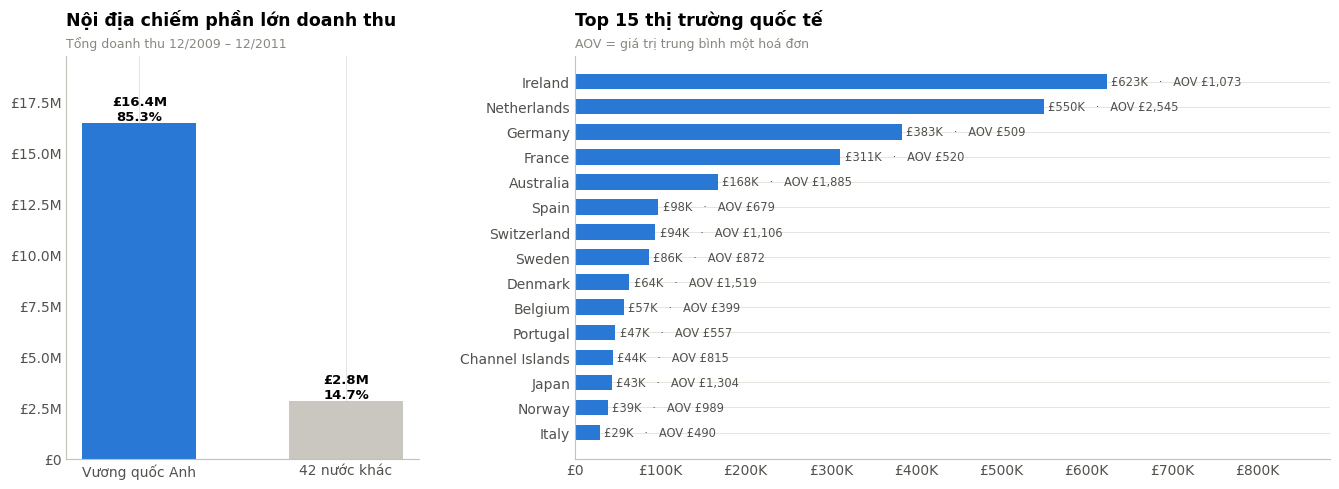

,revenue,customers,invoices,aov,share
Country,,,,,
United Kingdom,"16,449,138.86",5334,36179,454.66,0.853
Ireland,"623,414.16",3,581,"1,073.00",0.032
Netherlands,"549,773.41",22,216,"2,545.25",0.029
Germany,"383,289.00",107,753,509.02,0.020
France,"311,090.29",93,598,520.22,0.016
Australia,"167,800.01",15,89,"1,885.39",0.009
Spain,"97,766.75",38,144,678.94,0.005
Switzerland,"94,024.59",22,85,"1,106.17",0.005


In [30]:
# MỤC ĐÍCH: Phân tích đóng góp doanh thu theo quốc gia/thị trường.

# ============================================================
# 3.5 Thị trường: tỷ trọng nội địa và top 15 thị trường quốc tế
# ============================================================
ctry = sales.groupby("Country").agg(revenue=("Revenue", "sum"), customers=("Customer ID", "nunique"),
                                    invoices=("Invoice", "nunique")).sort_values("revenue", ascending=False)
ctry["aov"] = ctry.revenue / ctry.invoices
ctry["share"] = ctry.revenue / ctry.revenue.sum()
ctry.to_csv(OUT_DIR / "country_kpis.csv")

fig, axes = plt.subplots(1, 2, figsize=(13.5, 5), gridspec_kw={"width_ratios": [0.7, 1.5]})
ax = axes[0]
uk, other = ctry.loc["United Kingdom", "revenue"], ctry.drop("United Kingdom").revenue.sum()
ax.bar(["Vương quốc Anh", f"{len(ctry)-1} nước khác"], [uk, other], color=[C["blue"], NEUTRAL], width=0.55)
for i, v in enumerate([uk, other]):
    ax.text(i, v, f"£{v/1e6:.1f}M\n{v/(uk+other):.1%}", ha="center", va="bottom", fontsize=9.5, fontweight="bold")
ax.yaxis.set_major_formatter(GBP); ax.set_ylim(0, uk * 1.2); clean_axis(ax)
ax.set_title("Nội địa chiếm phần lớn doanh thu"); subtitle(ax, "Tổng doanh thu 12/2009 – 12/2011")
ax = axes[1]
top = ctry.drop("United Kingdom").head(15).iloc[::-1]
ax.barh(top.index, top.revenue, color=C["blue"], height=0.62)
for i, (v, a) in enumerate(zip(top.revenue, top.aov)):
    ax.text(v + 5000, i, f"£{v/1e3:,.0f}K   ·   AOV £{a:,.0f}", va="center", fontsize=8.3, color=INK2)
ax.xaxis.set_major_formatter(GBP); ax.set_xlim(0, top.revenue.max() * 1.42); clean_axis(ax, "y")
ax.set_title("Top 15 thị trường quốc tế"); subtitle(ax, "AOV = giá trị trung bình một hoá đơn")
fig.tight_layout(w_pad=3)
save_fig(fig, "fig09_countries")
FACTS.update(uk_share=float(uk / (uk + other)), top_intl=ctry.drop("United Kingdom").head(5).index.tolist(),
             top_intl_share=float(ctry.drop("United Kingdom").head(5).revenue.sum() / ctry.revenue.sum()),
             aov_uk=float(ctry.loc["United Kingdom", "aov"]),
             aov_intl=float(ctry.drop("United Kingdom").revenue.sum() / ctry.drop("United Kingdom").invoices.sum()))
ctry.head(8)

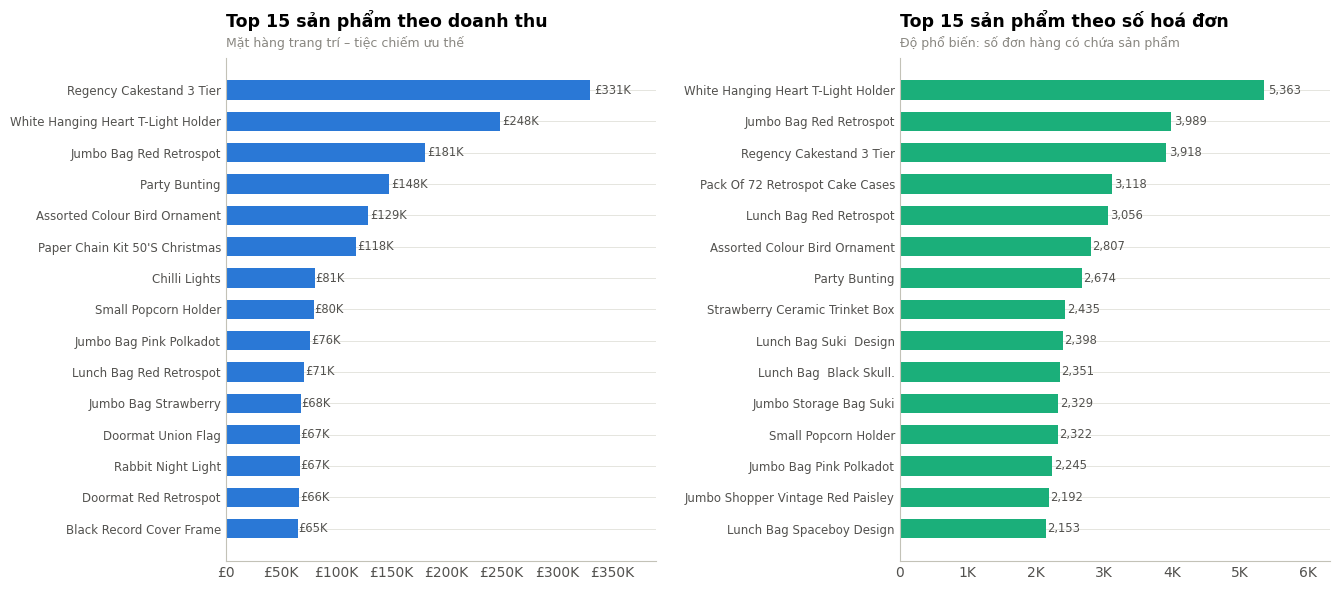

In [31]:
# MỤC ĐÍCH: Xếp hạng sản phẩm theo doanh thu và các chỉ tiêu bán hàng.

# ============================================================
# 3.6 Sản phẩm: top 15 theo doanh thu và theo độ phổ biến (số hoá đơn)
# ============================================================
prod = sales.groupby(["StockCode", "Description"]).agg(revenue=("Revenue", "sum"), qty=("Quantity", "sum"),
                                                        invoices=("Invoice", "nunique"),
                                                        price=("Price", "median")).reset_index()
prod = prod.sort_values("revenue", ascending=False)
prod.to_csv(OUT_DIR / "product_kpis.csv", index=False)
short = lambda s, n=36: (str(s).title() if len(str(s)) <= n else str(s).title()[:n - 1] + "…")

fig, axes = plt.subplots(1, 2, figsize=(13.5, 6))
for ax, col, title, colr in [(axes[0], "revenue", "Top 15 sản phẩm theo doanh thu", C["blue"]),
                             (axes[1], "invoices", "Top 15 sản phẩm theo số hoá đơn", C["aqua"])]:
    t = prod.nlargest(15, col).iloc[::-1]
    ax.barh([short(d) for d in t.Description], t[col], color=colr, height=0.62)
    for i, v in enumerate(t[col]):
        ax.text(v * 1.01, i, f"£{v/1e3:,.0f}K" if col == "revenue" else f"{v:,.0f}", va="center", fontsize=8.3, color=INK2)
    ax.xaxis.set_major_formatter(GBP if col == "revenue" else THOUS)
    ax.set_xlim(0, t[col].max() * 1.18); clean_axis(ax, "y"); ax.tick_params(axis="y", labelsize=8.5)
    ax.set_title(title)
subtitle(axes[0], "Mặt hàng trang trí – tiệc chiếm ưu thế")
subtitle(axes[1], "Độ phổ biến: số đơn hàng có chứa sản phẩm")
fig.tight_layout(w_pad=2)
save_fig(fig, "fig10_top_products")
FACTS.update(top_product_rev=prod.iloc[0].Description, top_product_rev_value=float(prod.iloc[0].revenue),
             top_product_freq=prod.nlargest(1, "invoices").Description.iloc[0],
             top_product_freq_n=int(prod.invoices.max()), n_products=len(prod))

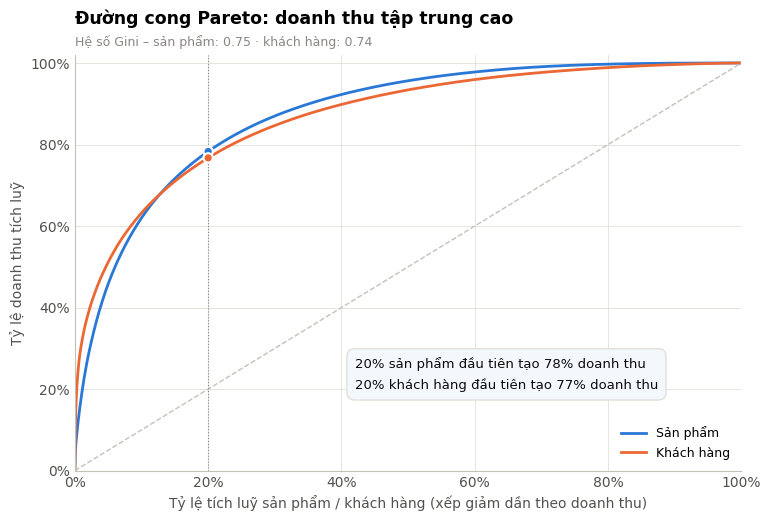

In [32]:
# MỤC ĐÍCH: Phân tích cơ cấu sản phẩm và trực quan hóa nhóm đóng góp nổi bật.

# ============================================================
# 3.7 Mức độ tập trung doanh thu: đường cong Pareto cho sản phẩm và khách hàng
# ============================================================
p_cum = prod.revenue.cumsum().values / prod.revenue.sum()
c_rev = cust.Monetary.sort_values(ascending=False)
c_cum = c_rev.cumsum().values / c_rev.sum()
p20, c20 = p_cum[int(len(p_cum) * .2) - 1], c_cum[int(len(c_cum) * .2) - 1]
gini = lambda x: 1 - 2 * np.trapezoid(np.r_[0, np.cumsum(np.sort(x)) / np.sum(x)], dx=1 / len(x)) if hasattr(np, "trapezoid") else 1 - 2 * np.trapz(np.r_[0, np.cumsum(np.sort(x)) / np.sum(x)], dx=1 / len(x))

fig, ax = plt.subplots(figsize=(8.6, 5.4))
ax.plot(np.r_[0, np.arange(1, len(p_cum) + 1) / len(p_cum)], np.r_[0, p_cum], color=C["blue"], label="Sản phẩm")
ax.plot(np.r_[0, np.arange(1, len(c_cum) + 1) / len(c_cum)], np.r_[0, c_cum], color=C["orange"], label="Khách hàng")
ax.plot([0, 1], [0, 1], color=AXIS, lw=1, ls="--"); ax.axvline(0.2, color=MUTED, lw=0.8, ls=":")
ax.scatter([0.2, 0.2], [p20, c20], color=[C["blue"], C["orange"]], s=45, zorder=3, edgecolor="white", linewidth=1.5)
ax.text(0.42, 0.2, f"20% sản phẩm đầu tiên tạo {p20:.0%} doanh thu\n20% khách hàng đầu tiên tạo {c20:.0%} doanh thu",
        fontsize=9.5, color=INK, linespacing=1.7, bbox=dict(facecolor="#f4f8fd", edgecolor=GRID, boxstyle="round,pad=0.6"))
ax.xaxis.set_major_formatter(PCT); ax.yaxis.set_major_formatter(PCT); ax.set_xlim(0, 1); ax.set_ylim(0, 1.02)
ax.set_xlabel("Tỷ lệ tích luỹ sản phẩm / khách hàng (xếp giảm dần theo doanh thu)")
ax.set_ylabel("Tỷ lệ doanh thu tích luỹ"); ax.legend(loc="lower right")
ax.set_title("Đường cong Pareto: doanh thu tập trung cao")
subtitle(ax, f"Hệ số Gini – sản phẩm: {gini(prod.revenue.values):.2f} · khách hàng: {gini(cust.Monetary.values):.2f}")
save_fig(fig, "fig11_pareto")
FACTS.update(products_top20_share=float(p20), customers_top20_share=float(c20),
             customers_top1_share=float(c_cum[int(len(c_cum) * .01) - 1]),
             gini_products=float(gini(prod.revenue.values)), gini_customers=float(gini(cust.Monetary.values)))

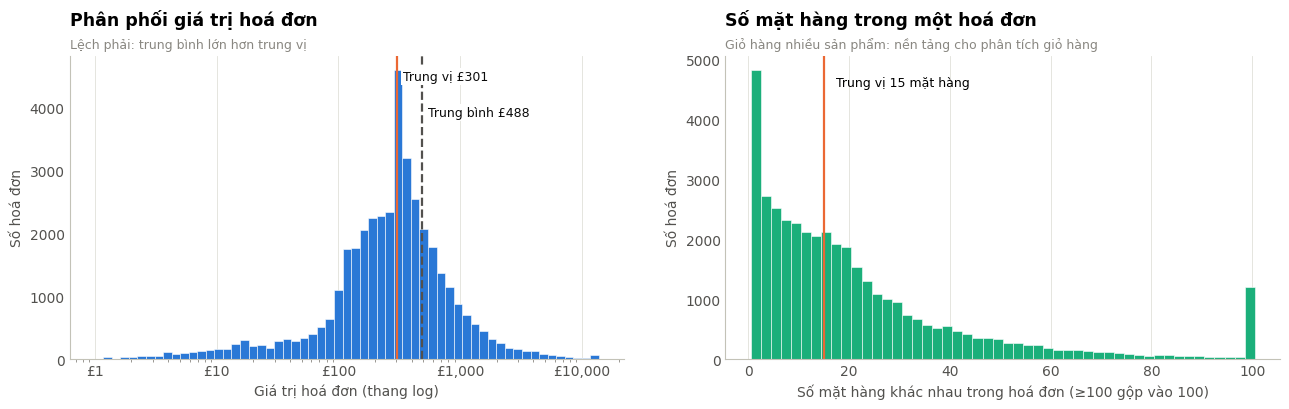

In [33]:
# MỤC ĐÍCH: Tổng hợp các kết quả phân tích thị trường và sản phẩm.

# ============================================================
# 3.8 Đặc điểm đơn hàng: phân phối giá trị hoá đơn và số mặt hàng / hoá đơn
# ============================================================
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
ax = axes[0]
bins = np.logspace(0, np.log10(inv_tbl.rev.quantile(0.999)), 60)
ax.hist(inv_tbl.rev.clip(upper=bins[-1]), bins=bins, color=C["blue"], edgecolor="white", linewidth=0.4)
ax.set_xscale("log"); clean_axis(ax)
ax.xaxis.set_major_formatter(mt.FuncFormatter(lambda v, p: f"£{v:,.0f}"))
for v, lab, colr, ls, h in [(inv_tbl.rev.median(), "Trung vị", C["orange"], "-", .92),
                            (inv_tbl.rev.mean(), "Trung bình", INK2, "--", .8)]:
    ax.axvline(v, color=colr, lw=1.6, ls=ls)
    ax.text(v * 1.12, ax.get_ylim()[1] * h, f"{lab} £{v:,.0f}", fontsize=9, color=INK,
            bbox=dict(facecolor="white", edgecolor="none", pad=1.5))
ax.set_xlabel("Giá trị hoá đơn (thang log)"); ax.set_ylabel("Số hoá đơn")
ax.set_title("Phân phối giá trị hoá đơn"); subtitle(ax, "Lệch phải: trung bình lớn hơn trung vị")
ax = axes[1]
ax.hist(inv_tbl["items"].clip(upper=100), bins=np.arange(0.5, 101.5, 2), color=C["aqua"], edgecolor="white", linewidth=0.4)
ax.axvline(inv_tbl["items"].median(), color=C["orange"], lw=1.6); clean_axis(ax)
ax.text(inv_tbl["items"].median() + 2.5, ax.get_ylim()[1] * .9, f"Trung vị {inv_tbl['items'].median():.0f} mặt hàng", fontsize=9)
ax.set_xlabel("Số mặt hàng khác nhau trong hoá đơn (≥100 gộp vào 100)"); ax.set_ylabel("Số hoá đơn")
ax.set_title("Số mặt hàng trong một hoá đơn"); subtitle(ax, "Giỏ hàng nhiều sản phẩm: nền tảng cho phân tích giỏ hàng")
fig.tight_layout(w_pad=3)
save_fig(fig, "fig12_order_distribution")
FACTS.update(aov_mean=float(inv_tbl.rev.mean()), aov_median=float(inv_tbl.rev.median()),
             items_median=float(inv_tbl["items"].median()), single_item_share=float((inv_tbl["items"] == 1).mean()))

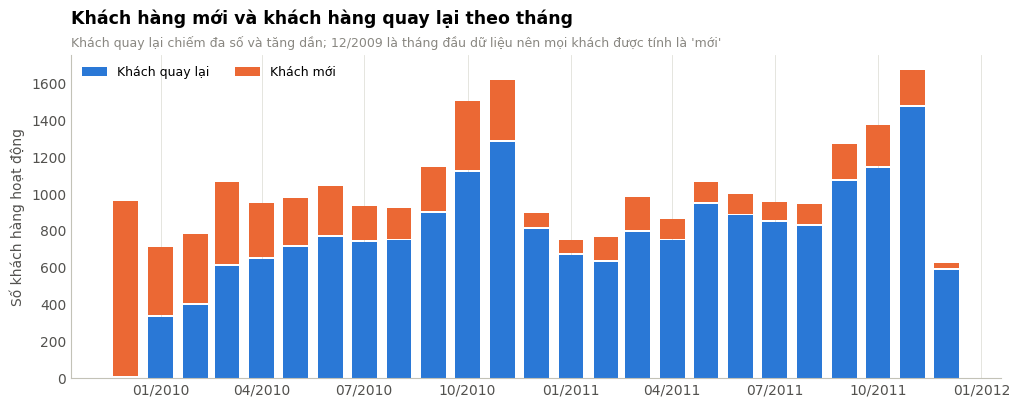

In [34]:
# MỤC ĐÍCH: Tính các chỉ số hành vi khách hàng, tần suất mua lại và tỷ lệ hủy.

# ============================================================
# 3.9 Khách mới và khách quay lại theo tháng
# ============================================================
first_month = customers_tx.groupby("Customer ID").YearMonth.min().rename("Cohort")
ct = customers_tx.join(first_month, on="Customer ID")
ct["IsNew"] = ct.YearMonth == ct.Cohort
nm = ct.groupby(["YearMonth", "IsNew"])["Customer ID"].nunique().unstack(fill_value=0)
nm.index = nm.index.to_timestamp(); nm.columns = ["Khách quay lại", "Khách mới"]
fig, ax = plt.subplots(figsize=(12, 4.2))
ax.bar(nm.index, nm["Khách quay lại"], width=22, color=C["blue"], label="Khách quay lại")
ax.bar(nm.index, nm["Khách mới"], width=22, bottom=nm["Khách quay lại"] + 10, color=C["orange"], label="Khách mới")
ax.xaxis.set_major_formatter(MONTH_FMT); ax.legend(loc="upper left", ncol=2); clean_axis(ax)
ax.set_ylabel("Số khách hàng hoạt động")
ax.set_title("Khách hàng mới và khách hàng quay lại theo tháng")
subtitle(ax, "Khách quay lại chiếm đa số và tăng dần; 12/2009 là tháng đầu dữ liệu nên mọi khách được tính là 'mới'")
save_fig(fig, "fig13_new_vs_returning")
FACTS["returning_share_2011"] = float(nm.loc["2011", "Khách quay lại"].sum() / nm.loc["2011"].sum().sum())

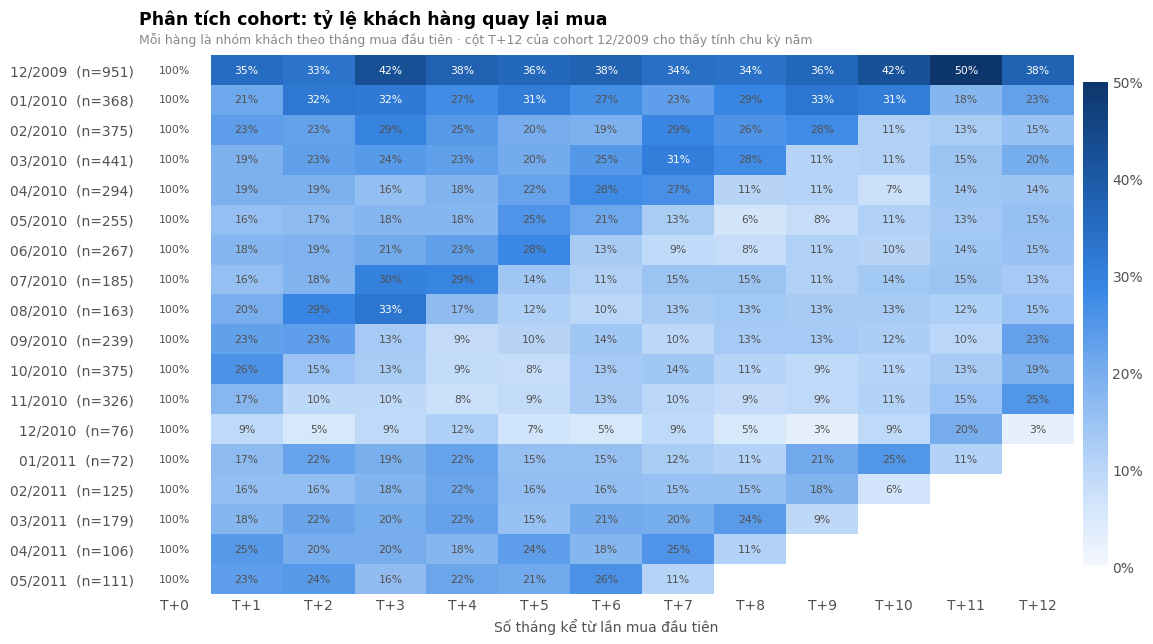

Tỷ lệ quay lại T+1 trung bình (trừ cohort 12/2009): 19.2%
Cohort 12/2009: T+1 = 35.0%, T+11 = 49.6%, T+12 = 37.6%


In [35]:
# MỤC ĐÍCH: Phân tích hành vi quay lại mua và tình trạng hủy hóa đơn.

# ============================================================
# 3.10 Phân tích cohort: tỷ lệ khách quay lại theo tháng kể từ lần mua đầu
# ============================================================
ct["Period"] = (ct.YearMonth.dt.year - ct.Cohort.dt.year) * 12 + (ct.YearMonth.dt.month - ct.Cohort.dt.month)
coh = ct.groupby(["Cohort", "Period"])["Customer ID"].nunique().unstack()
size = coh[0]
ret = coh.divide(size, axis=0).loc[:"2011-05", :12]
ret.to_csv(OUT_DIR / "cohort_retention.csv")
fig, ax = plt.subplots(figsize=(12.5, 7))
v = ret.values.copy(); v[:, 0] = np.nan
im = ax.imshow(v, cmap=CMAP_SEQ, aspect="auto", vmin=0, vmax=0.5)
for i in range(ret.shape[0]):
    for j in range(ret.shape[1]):
        x = ret.values[i, j]
        if not np.isnan(x):
            ax.text(j, i, f"{x:.0%}", ha="center", va="center", fontsize=7.8,
                    color="white" if (j > 0 and x > 0.3) else INK2)
ax.set_xticks(range(ret.shape[1]), [f"T+{k}" for k in ret.columns])
ax.set_yticks(range(ret.shape[0]), [f"{p.strftime('%m/%Y')}  (n={int(size[p]):,})" for p in ret.index])
ax.grid(False); [s.set_visible(False) for s in ax.spines.values()]
cb = fig.colorbar(im, ax=ax, fraction=0.025, pad=0.01, format=PCT); cb.outline.set_visible(False)
ax.set_xlabel("Số tháng kể từ lần mua đầu tiên")
ax.set_title("Phân tích cohort: tỷ lệ khách hàng quay lại mua")
subtitle(ax, "Mỗi hàng là nhóm khách theo tháng mua đầu tiên · cột T+12 của cohort 12/2009 cho thấy tính chu kỳ năm")
save_fig(fig, "fig14_cohort")
FACTS.update(ret_m1_mean_excl_first=float(ret.iloc[1:][1].mean()), ret_m3_mean_excl_first=float(ret.iloc[1:][3].mean()),
             ret_dec09_m1=float(ret.iloc[0][1]), ret_dec09_m12=float(ret.iloc[0][12]),
             ret_dec09_m11=float(ret.iloc[0][11]))
print(f"Tỷ lệ quay lại T+1 trung bình (trừ cohort 12/2009): {FACTS['ret_m1_mean_excl_first']:.1%}")
print(f"Cohort 12/2009: T+1 = {FACTS['ret_dec09_m1']:.1%}, T+11 = {FACTS['ret_dec09_m11']:.1%}, T+12 = {FACTS['ret_dec09_m12']:.1%}")

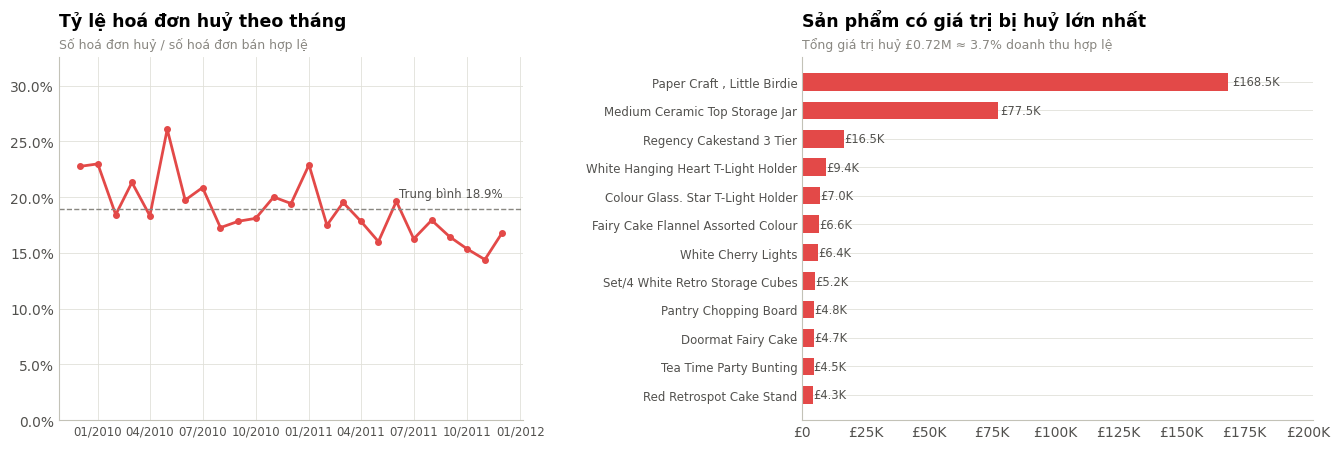

In [36]:
# MỤC ĐÍCH: Trực quan hóa kết quả phân tích khách hàng và hủy giao dịch.

# ============================================================
# 3.11 Huỷ đơn: tỷ lệ theo tháng và sản phẩm bị huỷ nhiều nhất
# ============================================================
rate = (cancels.groupby("YearMonth").Invoice.nunique() / sales.groupby("YearMonth").Invoice.nunique()).dropna()
rate.index = rate.index.to_timestamp()
cval = -cancels.Revenue.sum()
fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.6), gridspec_kw={"width_ratios": [1, 1.1]})
ax = axes[0]
ax.plot(rate.index, rate.values, color=C["red"], marker="o", ms=4)
ax.axhline(rate.mean(), color=MUTED, ls="--", lw=1)
ax.text(rate.index[-1], rate.mean() * 1.04, f"Trung bình {rate.mean():.1%}", color=INK2, fontsize=8.5, va="bottom", ha="right")
ax.xaxis.set_major_locator(md.MonthLocator(bymonth=[1, 4, 7, 10]))
ax.yaxis.set_major_formatter(PCT); ax.xaxis.set_major_formatter(MONTH_FMT); ax.set_ylim(0, rate.max() * 1.25)
ax.tick_params(axis="x", labelsize=8.5)
ax.set_title("Tỷ lệ hoá đơn huỷ theo tháng"); subtitle(ax, "Số hoá đơn huỷ / số hoá đơn bán hợp lệ")
ax = axes[1]
t = cancels.assign(V=-cancels.Revenue).groupby("Description").V.sum().nlargest(12).iloc[::-1]
ax.barh([short(d) for d in t.index], t.values, color=C["red"], height=0.62)
for i, x in enumerate(t.values):
    ax.text(x * 1.01, i, f"£{x/1e3:,.1f}K", va="center", fontsize=8.3, color=INK2)
ax.xaxis.set_major_formatter(GBP); ax.set_xlim(0, t.max() * 1.2); clean_axis(ax, "y"); ax.tick_params(axis="y", labelsize=8.5)
ax.set_title("Sản phẩm có giá trị bị huỷ lớn nhất")
subtitle(ax, f"Tổng giá trị huỷ £{cval/1e6:.2f}M ≈ {cval/sales.Revenue.sum():.1%} doanh thu hợp lệ")
fig.tight_layout(w_pad=3)
save_fig(fig, "fig15_cancellations")
FACTS.update(cancel_invoices=int(cancels.Invoice.nunique()), cancel_value=float(cval),
             cancel_value_share=float(cval / sales.Revenue.sum()), cancel_rate_mean=float(rate.mean()),
             cancel_rate_max_month=rate.idxmax().strftime("%m/%Y"), cancel_rate_max=float(rate.max()))

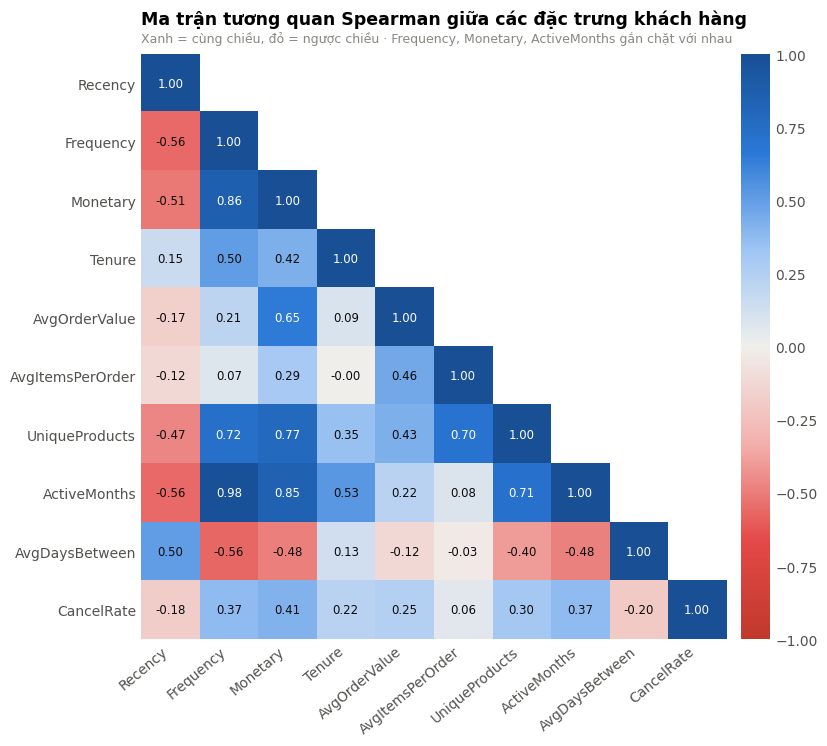

,Recency,Frequency,Monetary,Tenure,AvgOrderValue,AvgItemsPerOrder,UniqueProducts,ActiveMonths,AvgDaysBetween,CancelRate
Recency,1.000,-0.560,-0.510,0.150,-0.170,-0.120,-0.470,-0.560,0.500,-0.180
Frequency,-0.560,1.000,0.860,0.500,0.210,0.070,0.720,0.980,-0.560,0.370
Monetary,-0.510,0.860,1.000,0.420,0.650,0.290,0.770,0.850,-0.480,0.410
Tenure,0.150,0.500,0.420,1.000,0.090,-0.000,0.350,0.530,0.130,0.220
AvgOrderValue,-0.170,0.210,0.650,0.090,1.000,0.460,0.430,0.220,-0.120,0.250
AvgItemsPerOrder,-0.120,0.070,0.290,-0.000,0.460,1.000,0.700,0.080,-0.030,0.060
UniqueProducts,-0.470,0.720,0.770,0.350,0.430,0.700,1.000,0.710,-0.400,0.300
ActiveMonths,-0.560,0.980,0.850,0.530,0.220,0.080,0.710,1.000,-0.480,0.370
AvgDaysBetween,0.500,-0.560,-0.480,0.130,-0.120,-0.030,-0.400,-0.480,1.000,-0.200
CancelRate,-0.180,0.370,0.410,0.220,0.250,0.060,0.300,0.370,-0.200,1.000


In [37]:
# MỤC ĐÍCH: Tính tương quan Spearman giữa các đặc trưng khách hàng.

# ============================================================
# 3.12 Ma trận tương quan Spearman giữa các đặc trưng khách hàng
# ============================================================
num_cols = ["Recency", "Frequency", "Monetary", "Tenure", "AvgOrderValue", "AvgItemsPerOrder",
            "UniqueProducts", "ActiveMonths", "AvgDaysBetween", "CancelRate"]
corr = cust[num_cols].corr(method="spearman")
fig, ax = plt.subplots(figsize=(9.5, 7.6))
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
im = ax.imshow(np.where(mask, np.nan, corr.values), cmap=CMAP_DIV, vmin=-1, vmax=1)
for i in range(len(corr)):
    for j in range(i + 1):
        x = corr.values[i, j]
        ax.text(j, i, f"{x:.2f}", ha="center", va="center", fontsize=8.5, color="white" if abs(x) > 0.6 else INK)
ax.set_xticks(range(len(corr)), corr.columns, rotation=40, ha="right"); ax.set_yticks(range(len(corr)), corr.columns)
ax.grid(False); [s.set_visible(False) for s in ax.spines.values()]
cb = fig.colorbar(im, ax=ax, fraction=0.04, pad=0.02); cb.outline.set_visible(False)
ax.set_title("Ma trận tương quan Spearman giữa các đặc trưng khách hàng")
subtitle(ax, "Xanh = cùng chiều, đỏ = ngược chiều · Frequency, Monetary, ActiveMonths gắn chặt với nhau")
save_fig(fig, "fig16_correlation")
corr.to_csv(OUT_DIR / "correlation_spearman.csv")
FACTS["corr"] = corr.round(3).to_dict()
corr.round(2)

In [38]:
# MỤC ĐÍCH: Thiết lập các giả thuyết và nhóm dữ liệu đầu vào cho kiểm định thống kê.

# ============================================================
# 3.13 Kiểm tra giả định phân phối chuẩn (D'Agostino–Pearson) cho các biến dùng trong kiểm định
# ============================================================
# Tạo lịch liên tục từ ngày đầu đến ngày cuối quan sát; ngày không có giao dịch = 0.
# Nếu chỉ groupby ngày có giao dịch, ngày 0 doanh thu sẽ bị bỏ khỏi mẫu kiểm định.
calendar = pd.date_range(sales.Date.min(), sales.Date.max(), freq="D", name="Date")
daily = sales.groupby("Date").Revenue.sum().reindex(calendar, fill_value=0).to_frame("rev")
daily["Weekday"] = daily.index.dayofweek
daily["Peak"] = daily.index.month.isin([9, 10, 11])
norm_tbl = pd.DataFrame([
    {"Biến": n_, "n": len(x_), "Skewness": stats.skew(x_), "Kurtosis": stats.kurtosis(x_),
     "p-value (normaltest)": stats.normaltest(x_).pvalue}
    for n_, x_ in [("Giá trị hoá đơn", inv_tbl.rev), ("Doanh thu ngày", daily.rev),
                   ("Monetary khách hàng", cust.Monetary), ("Frequency khách hàng", cust.Frequency)]
]).set_index("Biến")
norm_tbl

,n,Skewness,Kurtosis,p-value (normaltest)
Biến,,,,
Giá trị hoá đơn,39511,18.23,599.10,0.000
Doanh thu ngày,739,0.779,1.117,0.000
Monetary khách hàng,5852,26.32,906.41,0.000
Frequency khách hàng,5852,12.04,239.97,0.000


In [39]:
# MỤC ĐÍCH: Thực hiện các kiểm định giả thuyết H1–H6 và tổng hợp kích thước hiệu ứng.

# ============================================================
# 3.14 Thực hiện 6 kiểm định giả thuyết
# Lưu ý: Mann–Whitney/Kruskal–Wallis so sánh phân phối/thứ hạng,
# không mặc nhiên là kiểm định chênh lệch trung vị nếu hình dạng phân phối khác nhau.
# ============================================================
results = []


def add(h, test, stat, p, effect, note):
    results.append({"Giả thuyết": h, "Kiểm định": test, "Thống kê": stat, "p-value": p,
                    "Kết luận (α=0,05)": "Bác bỏ H₀" if p < 0.05 else "Chưa đủ cơ sở bác bỏ H₀",
                    "Độ lớn hiệu ứng": effect, "Diễn giải": note})


# H1: giá trị hoá đơn quốc tế > Anh
a, b = inv_tbl[inv_tbl.country != "United Kingdom"].rev, inv_tbl[inv_tbl.country == "United Kingdom"].rev
u = stats.mannwhitneyu(a, b, alternative="greater")
rbc = 2 * u.statistic / (len(a) * len(b)) - 1
add("H1", "Mann–Whitney U (một phía)", u.statistic, u.pvalue, f"rank-biserial r = {rbc:.2f}",
    f"Trung vị mô tả: quốc tế £{a.median():,.0f}; Anh £{b.median():,.0f}. Kết quả kiểm định phản ánh khác biệt phân phối/thứ hạng.")
FACTS["h1"] = dict(med_intl=float(a.median()), med_uk=float(b.median()), p=float(u.pvalue), r=float(rbc))

# H2: doanh thu ngày mùa cao điểm > ngoài mùa; daily đã gồm cả ngày không có giao dịch (doanh thu 0)
a, b = daily[daily.Peak].rev, daily[~daily.Peak].rev
u = stats.mannwhitneyu(a, b, alternative="greater")
rbc = 2 * u.statistic / (len(a) * len(b)) - 1
add("H2", "Mann–Whitney U (một phía)", u.statistic, u.pvalue, f"rank-biserial r = {rbc:.2f}",
    f"Trung vị mô tả: T9–T11 £{a.median():,.0f}; các tháng còn lại £{b.median():,.0f}. Ngày không giao dịch được tính doanh thu 0.")
FACTS["h2"] = dict(med_peak=float(a.median()), med_off=float(b.median()), p=float(u.pvalue), r=float(rbc),
                   n_peak=int(len(a)), n_off=int(len(b)))

# H3: doanh thu ngày khác nhau theo thứ. Thứ Bảy được loại khỏi kiểm định theo giả thuyết hoạt động
# của doanh nghiệp; các ngày còn lại vẫn bao gồm ngày doanh thu bằng 0.
groups_weekday = [g.rev.values for d, g in daily.groupby("Weekday") if d != 5 and len(g) > 5]
k = stats.kruskal(*groups_weekday)
eps2 = max(0.0, (k.statistic - len(groups_weekday) + 1) / (len(daily[daily.Weekday != 5]) - len(groups_weekday)))
med_wd = daily[daily.Weekday != 5].groupby("Weekday").rev.median()
add("H3", "Kruskal–Wallis", k.statistic, k.pvalue, f"epsilon-squared = {eps2:.3f}",
    f"Trung vị mô tả cao nhất {DAYS[med_wd.idxmax()]} (£{med_wd.max():,.0f}), thấp nhất {DAYS[med_wd.idxmin()]} (£{med_wd.min():,.0f}); Thứ Bảy loại theo phạm vi giả thuyết.")
FACTS["h3"] = dict(p=float(k.pvalue), eps2=float(eps2), best=DAYS[med_wd.idxmax()], worst=DAYS[med_wd.idxmin()],
                   med=med_wd.round(0).to_dict())

# H4: tần suất mua và giá trị trung bình hoá đơn
rho = stats.spearmanr(cust.Frequency, cust.AvgOrderValue)
rho_m = stats.spearmanr(cust.Frequency, cust.Monetary)
add("H4", "Spearman", rho.statistic, rho.pvalue, f"rho = {rho.statistic:.2f}",
    f"Frequency–AOV rho={rho.statistic:.2f}; đối chiếu Frequency–Monetary rho={rho_m.statistic:.2f}. Tương quan không hàm ý quan hệ nhân quả.")
FACTS["h4"] = dict(rho_aov=float(rho.statistic), p=float(rho.pvalue), rho_monetary=float(rho_m.statistic))

# H5: tỷ lệ hoá đơn huỷ theo nhóm quốc gia; mỗi invoice chỉ được đếm một lần
ci = cancels.groupby("Invoice").IsUK.first().value_counts()
si = sales.groupby("Invoice").IsUK.first().value_counts()
tab = pd.DataFrame({"Huỷ": ci, "Không huỷ": si}).fillna(0).astype(int).rename(index={True: "Anh", False: "Quốc tế"})
chi = stats.chi2_contingency(tab)
cramer = np.sqrt(chi.statistic / (tab.values.sum() * min(tab.shape[0]-1, tab.shape[1]-1)))
rates = tab["Huỷ"] / tab.sum(axis=1)
add("H5", "Chi-bình phương", chi.statistic, chi.pvalue, f"Cramér's V = {cramer:.3f}",
    f"Tỷ lệ hoá đơn huỷ: Anh {rates['Anh']:.1%}, quốc tế {rates['Quốc tế']:.1%}. Ý nghĩa thống kê cần được đọc cùng độ lớn hiệu ứng.")
FACTS["h5"] = dict(rate_uk=float(rates["Anh"]), rate_intl=float(rates["Quốc tế"]), p=float(chi.pvalue), v=float(cramer))

# H6: tổng Monetary tăng cơ học theo thời gian quan sát; do đó phân tích chính dùng chi tiêu/tháng hoạt động.
# Giữ Monetary_total để mô tả, nhưng không diễn giải nó như bằng chứng retention làm tăng chi tiêu.
cust["ActiveGroup"] = pd.cut(cust.ActiveMonths, [0, 1, 3, 6, np.inf], labels=["1 tháng", "2–3 tháng", "4–6 tháng", "≥7 tháng"])
cust["SpendPerActiveMonth"] = cust.Monetary / cust.ActiveMonths.clip(lower=1)
groups = [g.SpendPerActiveMonth.dropna().values for _, g in cust.groupby("ActiveGroup", observed=True)]
k = stats.kruskal(*groups)
eps2 = max(0.0, (k.statistic - len(groups) + 1) / (sum(map(len, groups)) - len(groups)))
med_g = cust.groupby("ActiveGroup", observed=True).SpendPerActiveMonth.median()
med_total = cust.groupby("ActiveGroup", observed=True).Monetary.median()
add("H6", "Kruskal–Wallis (chi tiêu/tháng hoạt động)", k.statistic, k.pvalue, f"epsilon-squared = {eps2:.3f}",
    "Trung vị chi tiêu/tháng hoạt động: " + ", ".join(f"{i} £{v:,.0f}" for i, v in med_g.items()) + ". Chỉ là khác biệt phân phối giữa các nhóm, không chứng minh thời gian duy trì gây ra chi tiêu cao hơn.")
FACTS["h6"] = dict(p=float(k.pvalue), eps2=float(eps2), med_per_active_month={str(i): float(v) for i, v in med_g.items()},
                   med_total_descriptive={str(i): float(v) for i, v in med_total.items()})

hyp = pd.DataFrame(results).set_index("Giả thuyết")
hyp.to_csv(OUT_DIR / "hypothesis_tests.csv")
pd.set_option("display.max_colwidth", 120)
hyp

,Kiểm định,Thống kê,p-value,"Kết luận (α=0,05)",Độ lớn hiệu ứng,Diễn giải
Giả thuyết,,,,,,
H1,Mann–Whitney U (một phía),"76,427,447.00",0.000,Bác bỏ H₀,rank-biserial r = 0.27,Trung vị mô tả: quốc tế £421; Anh £295. Kết quả kiểm định phản ánh khác biệt phân phối/thứ hạng.
H2,Mann–Whitney U (một phía),"73,516.00",0.000,Bác bỏ H₀,rank-biserial r = 0.45,"Trung vị mô tả: T9–T11 £38,422; các tháng còn lại £22,571. Ngày không giao dịch được tính doanh thu 0."
H3,Kruskal–Wallis,119.65,0.000,Bác bỏ H₀,epsilon-squared = 0.183,"Trung vị mô tả cao nhất Thứ 5 (£33,788), thấp nhất CN (£16,868); Thứ Bảy loại theo phạm vi giả thuyết."
H4,Spearman,0.209,0.000,Bác bỏ H₀,rho = 0.21,Frequency–AOV rho=0.21; đối chiếu Frequency–Monetary rho=0.86. Tương quan không hàm ý quan hệ nhân quả.
H5,Chi-bình phương,48.84,0.000,Bác bỏ H₀,Cramér's V = 0.032,"Tỷ lệ hoá đơn huỷ: Anh 15.4%, quốc tế 19.6%. Ý nghĩa thống kê cần được đọc cùng độ lớn hiệu ứng."
H6,Kruskal–Wallis (chi tiêu/tháng hoạt động),596.75,0.000,Bác bỏ H₀,epsilon-squared = 0.102,"Trung vị chi tiêu/tháng hoạt động: 1 tháng £239, 2–3 tháng £296, 4–6 tháng £325, ≥7 tháng £447. Chỉ là khác biệt phâ..."


In [40]:
# MỤC ĐÍCH: Thực hiện hậu kiểm từng cặp cho H6 và hiệu chỉnh p-value bằng Bonferroni.

# Hậu kiểm H6: so sánh chi tiêu/tháng hoạt động giữa từng cặp nhóm bằng Mann–Whitney,
# hiệu chỉnh Bonferroni. Đây vẫn là so sánh phân phối/thứ hạng, không phải quan hệ nhân quả.
labs = list(med_g.index)
pairs = []
all_pairs = list(combinations(labs, 2))
for lab_a, lab_b in all_pairs:
    va = cust.loc[cust.ActiveGroup == lab_a, "SpendPerActiveMonth"].dropna()
    vb = cust.loc[cust.ActiveGroup == lab_b, "SpendPerActiveMonth"].dropna()
    test = stats.mannwhitneyu(va, vb, alternative="two-sided")
    p_adj = min(test.pvalue * len(all_pairs), 1.0)
    pairs.append({"Cặp": f"{lab_a} vs {lab_b}", "p chưa hiệu chỉnh": test.pvalue,
                  "p Bonferroni": p_adj, "Có ý nghĩa ở 5%": p_adj < 0.05,
                  "Trung vị nhóm A (£/tháng)": va.median(), "Trung vị nhóm B (£/tháng)": vb.median()})
posthoc_h6 = pd.DataFrame(pairs)
posthoc_h6.to_csv(OUT_DIR / "h6_posthoc_spend_per_active_month.csv", index=False)
posthoc_h6

,Cặp,p chưa hiệu chỉnh,p Bonferroni,Có ý nghĩa ở 5%,Trung vị nhóm A (£/tháng),Trung vị nhóm B (£/tháng)
0,1 tháng vs 2–3 tháng,0.000,0.000,True,239.46,295.70
1,1 tháng vs 4–6 tháng,0.000,0.000,True,239.46,324.85
2,1 tháng vs ≥7 tháng,0.000,0.000,True,239.46,447.32
3,2–3 tháng vs 4–6 tháng,0.000,0.000,True,295.70,324.85
4,2–3 tháng vs ≥7 tháng,0.000,0.000,True,295.70,447.32
5,4–6 tháng vs ≥7 tháng,0.000,0.000,True,324.85,447.32


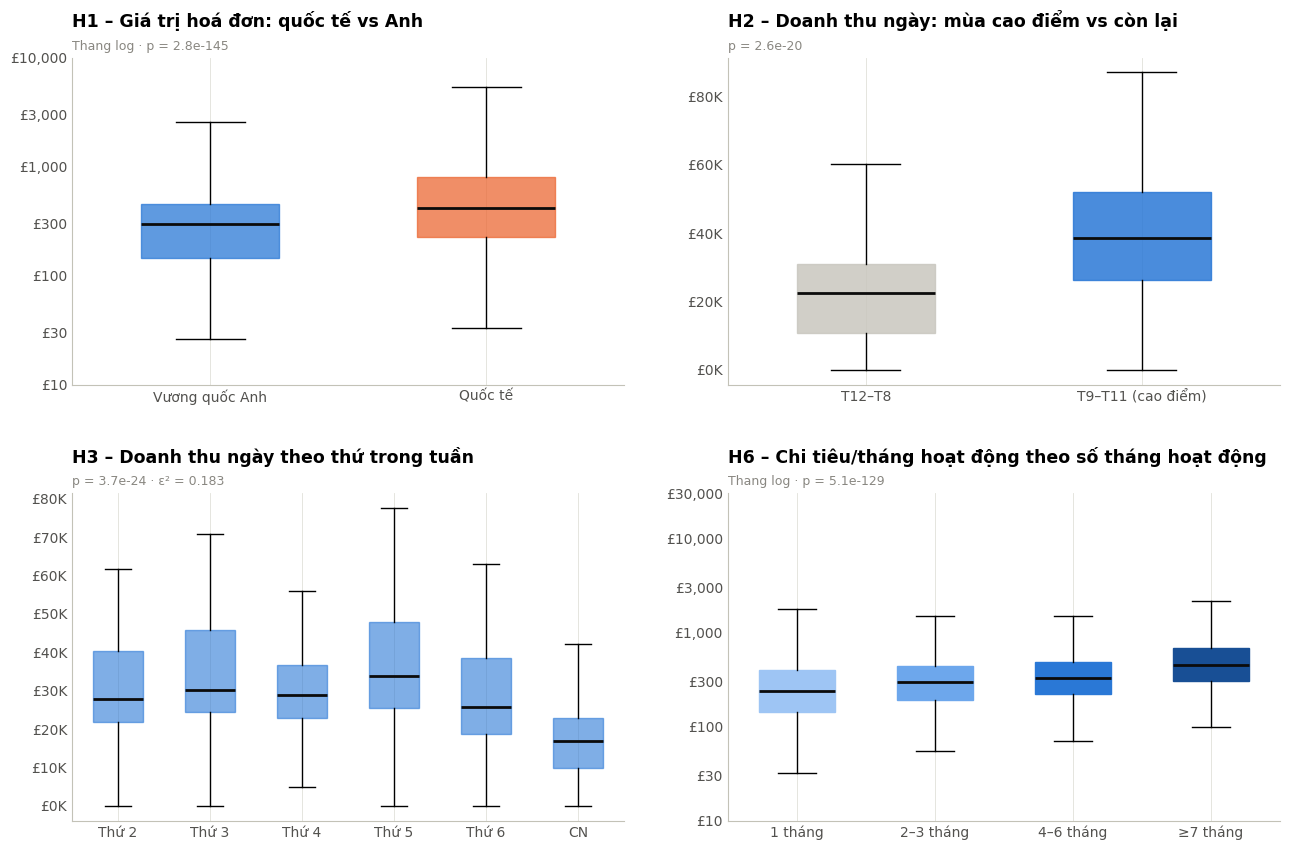

In [41]:
# MỤC ĐÍCH: Trực quan hóa kết quả kiểm định giả thuyết và so sánh các nhóm.

# Trực quan kết quả kiểm định H1, H2, H3, H6
fmt_p = lambda p: "p < 1e-300" if p == 0 else f"p = {p:.1e}"
LOG_TICKS = np.log10([10, 30, 100, 300, 1000, 3000, 10000, 30000])
fig, axes = plt.subplots(2, 2, figsize=(13, 8.6))
ax = axes[0, 0]   # H1
data = [np.log10(inv_tbl[inv_tbl.country == "United Kingdom"].rev), np.log10(inv_tbl[inv_tbl.country != "United Kingdom"].rev)]
bp = ax.boxplot(data, widths=0.5, patch_artist=True, showfliers=False, medianprops=dict(color=INK, lw=2))
for patch, colr in zip(bp["boxes"], [C["blue"], C["orange"]]):
    patch.set_facecolor(colr); patch.set_alpha(0.75); patch.set_edgecolor(colr)
ax.set_xticks([1, 2], ["Vương quốc Anh", "Quốc tế"])
ax.yaxis.set_major_formatter(mt.FuncFormatter(lambda x, p: f"£{10**x:,.0f}")); clean_axis(ax)
ax.set_yticks(LOG_TICKS[:-1])
ax.set_title("H1 – Giá trị hoá đơn: quốc tế vs Anh"); subtitle(ax, f"Thang log · {fmt_p(FACTS['h1']['p'])}")
ax = axes[0, 1]   # H2
data = [daily[~daily.Peak].rev / 1e3, daily[daily.Peak].rev / 1e3]
bp = ax.boxplot(data, widths=0.5, patch_artist=True, showfliers=False, medianprops=dict(color=INK, lw=2))
for patch, colr in zip(bp["boxes"], [NEUTRAL, C["blue"]]):
    patch.set_facecolor(colr); patch.set_alpha(0.85); patch.set_edgecolor(colr)
ax.set_xticks([1, 2], ["T12–T8", "T9–T11 (cao điểm)"]); clean_axis(ax)
ax.yaxis.set_major_formatter(mt.FuncFormatter(lambda v, p: f"£{v:.0f}K"))
ax.set_title("H2 – Doanh thu ngày: mùa cao điểm vs còn lại"); subtitle(ax, fmt_p(FACTS['h2']['p']))
ax = axes[1, 0]   # H3
d3 = daily[daily.Weekday != 5]
bp = ax.boxplot([g.rev / 1e3 for _, g in d3.groupby("Weekday")], widths=0.55, patch_artist=True, showfliers=False,
                medianprops=dict(color=INK, lw=2))
for patch in bp["boxes"]:
    patch.set_facecolor(C["blue"]); patch.set_alpha(0.6); patch.set_edgecolor(C["blue"])
ax.set_xticks(range(1, 7), [DAYS[d] for d in sorted(d3.Weekday.unique())]); clean_axis(ax)
ax.yaxis.set_major_formatter(mt.FuncFormatter(lambda v, p: f"£{v:.0f}K"))
ax.set_title("H3 – Doanh thu ngày theo thứ trong tuần"); subtitle(ax, f"{fmt_p(FACTS['h3']['p'])} · ε² = {FACTS['h3']['eps2']:.3f}")
ax = axes[1, 1]   # H6
bp = ax.boxplot([np.log10(g) for g in groups], widths=0.55, patch_artist=True, showfliers=False,
                medianprops=dict(color=INK, lw=2))
for patch, colr in zip(bp["boxes"], ["#9ec5f4", "#6da7ec", "#2a78d6", "#184f95"]):
    patch.set_facecolor(colr); patch.set_edgecolor(colr)
ax.set_xticks(range(1, 5), labs); clean_axis(ax); ax.set_yticks(LOG_TICKS)
ax.yaxis.set_major_formatter(mt.FuncFormatter(lambda x, p: f"£{10**x:,.0f}"))
ax.set_title("H6 – Chi tiêu/tháng hoạt động theo số tháng hoạt động"); subtitle(ax, f"Thang log · {fmt_p(FACTS['h6']['p'])}")
fig.tight_layout(h_pad=3, w_pad=3)
save_fig(fig, "fig17_hypothesis_tests")

In [42]:
# MỤC ĐÍCH: Tính Recency, Frequency, Monetary và chuẩn bị dữ liệu cho phân khúc khách hàng.

# ============================================================
# 3.15 Chuẩn bị dữ liệu: log1p + StandardScaler cho R, F, M
# ============================================================
rfm = cust[["Recency", "Frequency", "Monetary"]].copy()
X_rfm = StandardScaler().fit_transform(np.log1p(rfm))
print("Trung bình sau chuẩn hoá:", X_rfm.mean(axis=0).round(3), "| Độ lệch chuẩn:", X_rfm.std(axis=0).round(3))

# ============================================================
# 3.16 Chọn số cụm k từ 2 đến 10
# ============================================================
k_rows = []
for k in range(2, 11):
    km = KMeans(n_clusters=k, n_init=20, random_state=RANDOM_STATE).fit(X_rfm)
    k_rows.append({"k": k, "Inertia": km.inertia_, "Silhouette": silhouette_score(X_rfm, km.labels_),
                   "Davies-Bouldin": davies_bouldin_score(X_rfm, km.labels_)})
k_tbl = pd.DataFrame(k_rows).set_index("k")
k_tbl.to_csv(OUT_DIR / "kmeans_k_selection.csv")
k_tbl

Trung bình sau chuẩn hoá: [ 0.  0. -0.] | Độ lệch chuẩn: [1. 1. 1.]


,Inertia,Silhouette,Davies-Bouldin
k,,,
2,"8,561.58",0.439,0.873
3,"6,341.41",0.347,1.036
4,"4,935.25",0.365,0.940
5,"4,109.49",0.341,0.956
6,"3,562.58",0.336,0.957
7,"3,184.93",0.307,0.974
8,"2,895.12",0.307,0.968
9,"2,658.46",0.294,0.998
10,"2,465.21",0.290,1.000


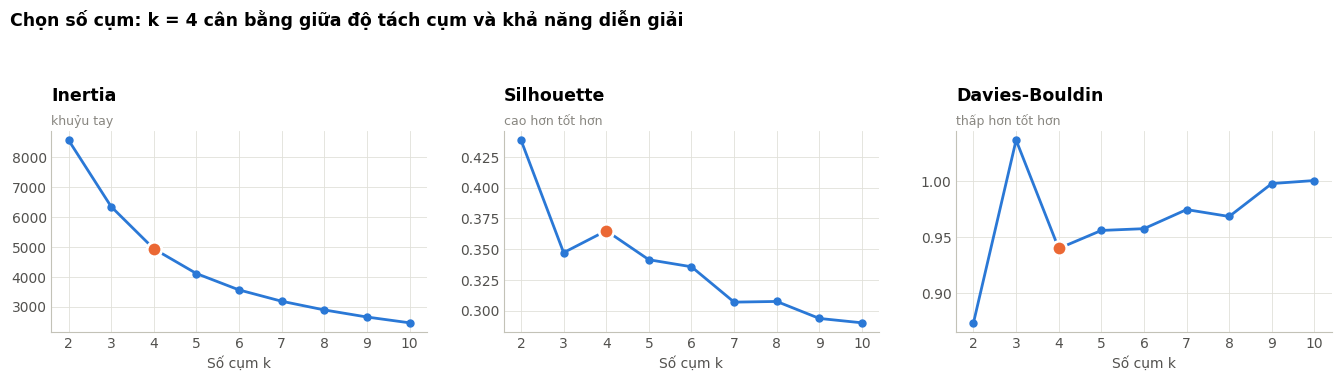

In [43]:
# MỤC ĐÍCH: Chọn số cụm K cuối cùng theo tiêu chí phân tích và giải trình ở phần Markdown.

K = 4   # lựa chọn cuối cùng – giải trình ở ô markdown bên dưới
fig, axes = plt.subplots(1, 3, figsize=(13.5, 3.8))
for ax, col, better in zip(axes, k_tbl.columns, ["khuỷu tay", "cao hơn tốt hơn", "thấp hơn tốt hơn"]):
    ax.plot(k_tbl.index, k_tbl[col], marker="o", ms=5, color=C["blue"])
    ax.scatter([K], [k_tbl.loc[K, col]], s=110, color=C["orange"], zorder=3, edgecolor="white", linewidth=2)
    ax.set_xticks(k_tbl.index); ax.set_xlabel("Số cụm k")
    ax.set_title(col); subtitle(ax, better)
fig.suptitle(f"Chọn số cụm: k = {K} cân bằng giữa độ tách cụm và khả năng diễn giải", x=0.01, ha="left",
             fontsize=12.5, fontweight="bold", y=0.99)
fig.tight_layout(w_pad=3, rect=(0, 0, 1, 0.92))
save_fig(fig, "fig18_kmeans_k_selection")

In [44]:
# MỤC ĐÍCH: Huấn luyện K-Means với số cụm đã chọn và gán nhãn phân khúc khách hàng.

# ============================================================
# 3.17 Huấn luyện K-Means với k = 4 và mô tả từng cụm
# ============================================================
km = KMeans(n_clusters=K, n_init=20, random_state=RANDOM_STATE).fit(X_rfm)
cust["Cluster"] = km.labels_
prof = cust.groupby("Cluster").agg(Số_khách=("Recency", "size"), Recency_TV=("Recency", "median"),
                                   Frequency_TV=("Frequency", "median"), Monetary_TV=("Monetary", "median"),
                                   Tổng_doanh_thu=("Monetary", "sum"))
prof["% khách"] = prof.Số_khách / prof.Số_khách.sum() * 100
prof["% doanh thu"] = prof.Tổng_doanh_thu / prof.Tổng_doanh_thu.sum() * 100

# Đặt tên cụm theo thứ hạng: điểm = −rank(Recency) + rank(Frequency) + rank(Monetary)
score = (-prof.Recency_TV.rank() + prof.Frequency_TV.rank() + prof.Monetary_TV.rank())
order = score.sort_values(ascending=False).index.tolist()
names = {order[0]: "Khách hàng VIP", order[-1]: "Khách đã rời bỏ"}
mid = order[1:-1]   # 2 cụm giữa: cụm có Recency thấp hơn = "mới / tiềm năng", cụm còn lại = "có nguy cơ rời bỏ"
mid_sorted = sorted(mid, key=lambda c: prof.loc[c, "Recency_TV"])
names[mid_sorted[0]], names[mid_sorted[1]] = "Khách mới / tiềm năng", "Khách có nguy cơ rời bỏ"
cust["Segment"] = cust.Cluster.map(names)
prof.index = prof.index.map(names)
SEG_ORDER = ["Khách hàng VIP", "Khách mới / tiềm năng", "Khách có nguy cơ rời bỏ", "Khách đã rời bỏ"]
SEG_COLOR = dict(zip(SEG_ORDER, [C["blue"], C["aqua"], C["orange"], C["violet"]]))
prof = prof.loc[SEG_ORDER]
prof.to_csv(OUT_DIR / "segment_profile.csv")
FACTS["segments"] = prof.round(2).to_dict(orient="index")
FACTS["kmeans"] = dict(k=K, silhouette=float(k_tbl.loc[K, "Silhouette"]), db=float(k_tbl.loc[K, "Davies-Bouldin"]),
                       sil_k2=float(k_tbl.loc[2, "Silhouette"]), sil_k3=float(k_tbl.loc[3, "Silhouette"]))
prof

,Số_khách,Recency_TV,Frequency_TV,Monetary_TV,Tổng_doanh_thu,% khách,% doanh thu
Cluster,,,,,,,
Khách hàng VIP,1112,15.00,13.00,"5,114.80","12,038,964.95",19.00,72.03
Khách mới / tiềm năng,1218,23.00,3.000,706.54,"1,000,911.35",20.81,5.989
Khách có nguy cơ rời bỏ,1477,158.00,5.000,"1,567.48","2,984,609.04",25.24,17.86
Khách đã rời bỏ,2045,399.00,1.000,289.48,"688,586.07",34.95,4.120


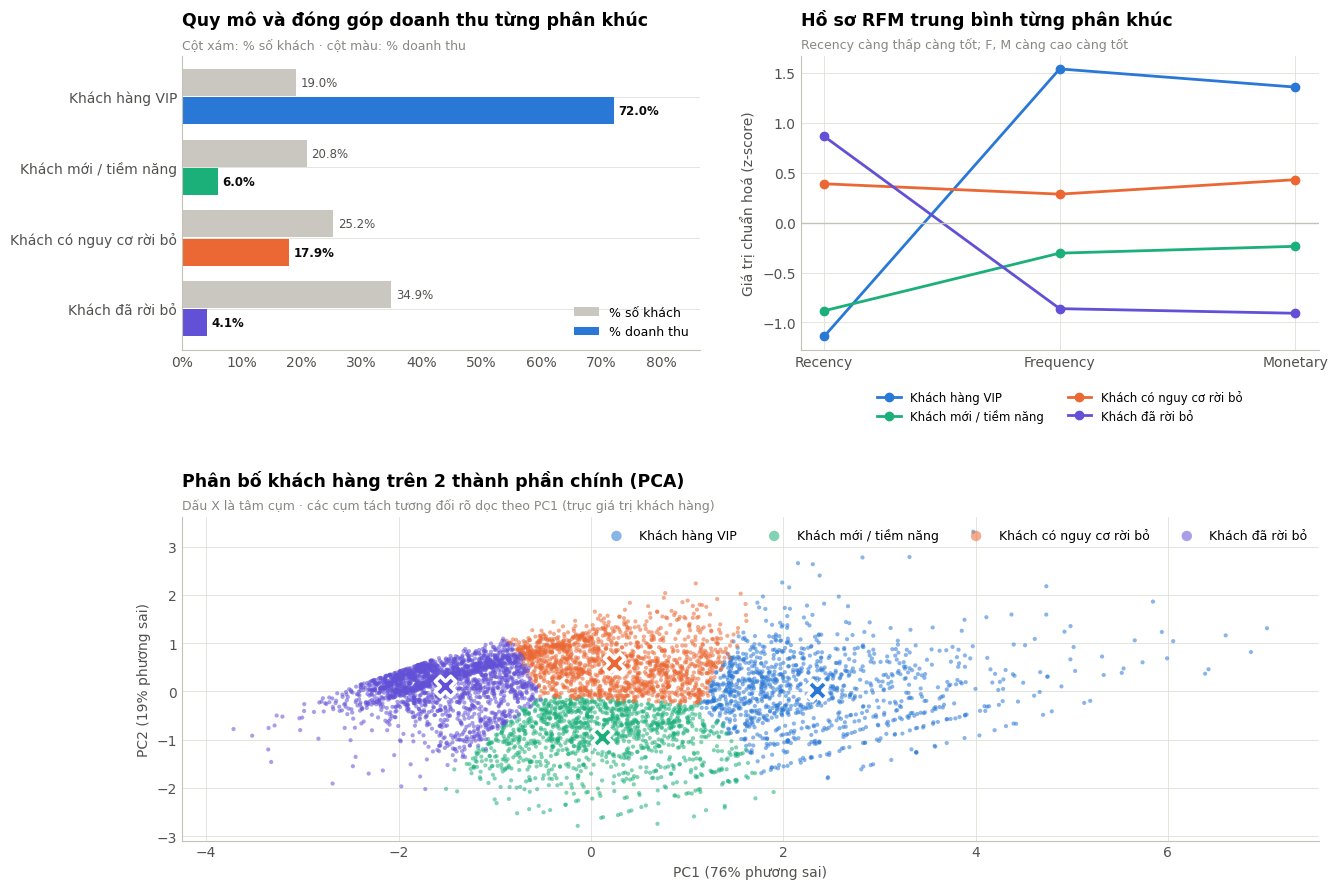

In [45]:
# MỤC ĐÍCH: Trực quan hóa quy mô, đóng góp doanh thu, hồ sơ RFM và PCA của các cụm.

# Trực quan phân khúc: (a) quy mô vs đóng góp doanh thu, (b) hồ sơ RFM chuẩn hoá (snake plot), (c) PCA 2D
fig = plt.figure(figsize=(13.5, 9))
gs = fig.add_gridspec(2, 2, height_ratios=[1, 1.1])
ax = fig.add_subplot(gs[0, 0])
y = np.arange(len(SEG_ORDER))[::-1]
ax.barh(y + 0.2, prof["% khách"], height=0.38, color=NEUTRAL, label="% số khách")
ax.barh(y - 0.2, prof["% doanh thu"], height=0.38, color=[SEG_COLOR[s] for s in SEG_ORDER], label="% doanh thu")
for yi, a_, b_ in zip(y, prof["% khách"], prof["% doanh thu"]):
    ax.text(a_ + 0.8, yi + 0.2, f"{a_:.1f}%", va="center", fontsize=8.5, color=INK2)
    ax.text(b_ + 0.8, yi - 0.2, f"{b_:.1f}%", va="center", fontsize=8.5, color=INK, fontweight="bold")
ax.set_yticks(y, SEG_ORDER); ax.xaxis.set_major_formatter(mt.PercentFormatter(100)); clean_axis(ax, "y")
ax.set_xlim(0, max(prof["% doanh thu"].max(), prof["% khách"].max()) * 1.2); ax.legend(loc="lower right")
ax.set_title("Quy mô và đóng góp doanh thu từng phân khúc"); subtitle(ax, "Cột xám: % số khách · cột màu: % doanh thu")

ax = fig.add_subplot(gs[0, 1])
z = pd.DataFrame(X_rfm, columns=["Recency", "Frequency", "Monetary"]).assign(Segment=cust.Segment.values)
zm = z.groupby("Segment").mean().loc[SEG_ORDER]
for s in SEG_ORDER:
    ax.plot(zm.columns, zm.loc[s], marker="o", ms=6, color=SEG_COLOR[s], label=s)
ax.axhline(0, color=AXIS, lw=1); ax.set_ylabel("Giá trị chuẩn hoá (z-score)")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=2, fontsize=8.5)
ax.set_title("Hồ sơ RFM trung bình từng phân khúc"); subtitle(ax, "Recency càng thấp càng tốt; F, M càng cao càng tốt")

ax = fig.add_subplot(gs[1, :])
pca = PCA(n_components=2, random_state=RANDOM_STATE).fit(X_rfm)
P = pca.transform(X_rfm)
for s in SEG_ORDER:
    m_ = (cust.Segment == s).values
    ax.scatter(P[m_, 0], P[m_, 1], s=9, alpha=0.55, color=SEG_COLOR[s], label=s, edgecolor="none")
cent = pca.transform(km.cluster_centers_)
for c_i, (x_, y_) in enumerate(cent):
    ax.scatter(x_, y_, s=220, color=SEG_COLOR[names[c_i]], edgecolor="white", linewidth=2.5, zorder=3, marker="X")
ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.0%} phương sai)")
ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.0%} phương sai)")
ax.legend(loc="upper right", markerscale=2.5, ncol=4)
ax.set_title("Phân bố khách hàng trên 2 thành phần chính (PCA)")
subtitle(ax, "Dấu X là tâm cụm · các cụm tách tương đối rõ dọc theo PC1 (trục giá trị khách hàng)")
fig.tight_layout(h_pad=3, w_pad=3)
save_fig(fig, "fig19_segments")
FACTS["pca_var"] = pca.explained_variance_ratio_.round(3).tolist()

In [46]:
# MỤC ĐÍCH: Tính các đặc điểm trung vị của từng phân khúc để hỗ trợ đề xuất kinh doanh.

# Đặc điểm hành vi bổ sung của từng phân khúc (giá trị trung vị) – phục vụ đề xuất hành động
seg_beh = cust.groupby("Segment")[["AvgOrderValue", "AvgItemsPerOrder", "UniqueProducts", "Tenure", "ActiveMonths",
                                   "AvgDaysBetween", "CancelRate"]].median().loc[SEG_ORDER]
seg_beh["% khách Anh"] = cust.groupby("Segment").Country.apply(lambda s: (s == "United Kingdom").mean() * 100)
seg_beh.to_csv(OUT_DIR / "segment_behaviour.csv")
FACTS["segment_behaviour"] = seg_beh.round(2).to_dict(orient="index")
seg_beh

,AvgOrderValue,AvgItemsPerOrder,UniqueProducts,Tenure,ActiveMonths,AvgDaysBetween,CancelRate,% khách Anh
Segment,,,,,,,,
Khách hàng VIP,363.60,19.45,168.00,681.00,10.00,43.14,0.143,91.01
Khách mới / tiềm năng,252.40,18.00,43.00,212.00,2.000,76.42,0.000,90.56
Khách có nguy cơ rời bỏ,320.63,18.00,68.00,621.00,4.000,87.50,0.111,89.84
Khách đã rời bỏ,203.52,14.00,18.00,444.00,1.000,298.00,0.000,92.52


In [47]:
# MỤC ĐÍCH: Chuyển dữ liệu giao dịch thành các giỏ hàng để khai phá luật kết hợp.

# ============================================================
# 3.18 Xây ma trận giỏ hàng nhị phân (hoá đơn × sản phẩm) dạng thưa
# Dùng tất cả hoá đơn bán (kể cả khách không ID) vì luật kết hợp chỉ cần nội dung giỏ hàng
# ============================================================
basket_tx = sales[["Invoice", "StockCode"]].drop_duplicates()
inv_idx = {v: i for i, v in enumerate(basket_tx.Invoice.unique())}
item_list = basket_tx.StockCode.unique()
item_idx = {v: i for i, v in enumerate(item_list)}
B = sparse.csr_matrix((np.ones(len(basket_tx), dtype=np.int32),
                       (basket_tx.Invoice.map(inv_idx).values, basket_tx.StockCode.map(item_idx).values)),
                      shape=(len(inv_idx), len(item_idx)))
N_INV = B.shape[0]
print(f"Ma trận giỏ hàng: {B.shape[0]:,} hoá đơn × {B.shape[1]:,} sản phẩm | mật độ {B.nnz / np.prod(B.shape):.3%}")

Ma trận giỏ hàng: 39,511 hoá đơn × 4,893 sản phẩm | mật độ 0.513%


In [48]:
# MỤC ĐÍCH: Sinh các tập mục phổ biến bằng thuật toán Apriori.

# ============================================================
# 3.19 Apriori: tìm tập phổ biến kích thước 1, 2, 3 với ngưỡng support tối thiểu
# ============================================================
MIN_SUPPORT, MIN_CONF, MIN_LIFT = 0.01, 0.5, 3.0


def apriori(B, min_support):
    """Trả về dict {frozenset(chỉ số sản phẩm): support} cho các tập phổ biến kích thước ≤ 3."""
    n = B.shape[0]
    sup1 = np.asarray(B.sum(axis=0)).ravel() / n
    L1 = np.where(sup1 >= min_support)[0]                       # bước 1: sản phẩm phổ biến
    freq = {frozenset([i]): sup1[i] for i in L1}
    Bs = B[:, L1].astype(np.int32)
    co = (Bs.T @ Bs).toarray() / n                              # bước 2: đếm cặp bằng nhân ma trận
    pairs = [(L1[a], L1[b]) for a, b in zip(*np.triu_indices(len(L1), 1)) if co[a, b] >= min_support]
    for a, b in pairs:
        freq[frozenset([a, b])] = co[np.searchsorted(L1, a), np.searchsorted(L1, b)]
    # bước 3: ứng viên bộ ba – mọi tập con 2 phần tử phải phổ biến (tính chất Apriori)
    pair_set = {frozenset(p) for p in pairs}
    items2 = sorted({i for p in pairs for i in p})
    cols = {i: B[:, i].toarray().ravel().astype(bool) for i in items2}
    cand = set()
    for (a, b) in pairs:
        for c in items2:
            if c not in (a, b) and frozenset([a, c]) in pair_set and frozenset([b, c]) in pair_set:
                cand.add(frozenset([a, b, c]))
    for t in cand:
        a, b, c = tuple(t)
        s = (cols[a] & cols[b] & cols[c]).mean()
        if s >= min_support:
            freq[t] = s
    return freq


freq = apriori(B, MIN_SUPPORT)
print("Số tập phổ biến theo kích thước:", pd.Series([len(k) for k in freq]).value_counts().sort_index().to_dict())

Số tập phổ biến theo kích thước: {1: 706, 2: 523, 3: 107}


In [49]:
# MỤC ĐÍCH: Tạo và sàng lọc luật kết hợp theo support, confidence và lift.

# ============================================================
# 3.20 Sinh luật kết hợp A → B và lọc theo confidence, lift
# ============================================================
desc_of = sales.drop_duplicates("StockCode").set_index("StockCode").Description
rules = []
for itemset, sup in freq.items():
    if len(itemset) < 2:
        continue
    for r in range(1, len(itemset)):
        for ante in combinations(itemset, r):
            ante = frozenset(ante); cons = itemset - ante
            conf = sup / freq[ante]
            lift = conf / freq[cons]
            rules.append({"Antecedent": " + ".join(str(desc_of[item_list[i]]).title() for i in ante),
                          "Consequent": " + ".join(str(desc_of[item_list[i]]).title() for i in cons),
                          "Support": sup, "Confidence": conf, "Lift": lift, "Size": len(itemset),
                          "Leverage": sup - freq[ante] * freq[cons]})
rules = pd.DataFrame(rules)
strong = rules[(rules.Confidence >= MIN_CONF) & (rules.Lift >= MIN_LIFT)].sort_values("Lift", ascending=False)
rules.to_csv(OUT_DIR / "association_rules_all.csv", index=False)
strong.to_csv(OUT_DIR / "association_rules_strong.csv", index=False)
FACTS["rules"] = dict(n_all=len(rules), n_strong=len(strong), lift_median_strong=float(strong.Lift.median()),
                      top=strong.head(10)[["Antecedent", "Consequent", "Support", "Confidence", "Lift"]].round(3).to_dict(orient="records"))
print(f"Tổng số luật: {len(rules):,} | Luật mạnh (conf ≥ {MIN_CONF}, lift ≥ {MIN_LIFT}): {len(strong):,}")
# Mỗi tập sản phẩm chỉ hiển thị 1 chiều luật có confidence cao nhất để tránh lặp A→B và B→A
strong["Itemset"] = strong.apply(lambda r: " | ".join(sorted((r.Antecedent + " + " + r.Consequent).split(" + "))), axis=1)
top_rules = (strong.sort_values("Confidence", ascending=False).drop_duplicates("Itemset")
             .sort_values("Lift", ascending=False).head(15))
top_rules.to_csv(OUT_DIR / "association_rules_top15.csv", index=False)
FACTS["rules"]["top_unique"] = top_rules[["Antecedent", "Consequent", "Support", "Confidence", "Lift"]].round(4).to_dict(orient="records")
FACTS["rules"]["n_unique_itemsets"] = int(strong.Itemset.nunique())
top_rules[["Antecedent", "Consequent", "Support", "Confidence", "Lift"]].reset_index(drop=True)

Tổng số luật: 1,688 | Luật mạnh (conf ≥ 0.5, lift ≥ 3.0): 412


,Antecedent,Consequent,Support,Confidence,Lift
0,Poppy'S Playhouse Bedroom + Poppy'S Playhouse Livingroom,Poppy'S Playhouse Kitchen,0.010,0.887,47.24
1,Poppy'S Playhouse Livingroom,Poppy'S Playhouse Bedroom,0.012,0.817,45.94
2,Poppy'S Playhouse Livingroom,Poppy'S Playhouse Kitchen,0.012,0.840,44.75
3,Poppy'S Playhouse Bedroom,Poppy'S Playhouse Kitchen,0.014,0.792,42.19
4,Small Marshmallows Pink Bowl,Small Dolly Mix Design Orange Bowl,0.012,0.762,41.51
5,Wooden Tree Christmas Scandinavian,Wooden Star Christmas Scandinavian,0.011,0.790,40.65
6,Set/10 Blue Spotty Party Candles,Set/10 Pink Polkadot Party Candles,0.012,0.776,37.99
7,"Key Fob , Garage Design","Key Fob , Back Door",0.010,0.646,37.12
8,Feltcraft Princess Lola Doll,Feltcraft Princess Charlotte Doll,0.010,0.620,35.75
9,Pink Polkadot Cup,Blue Polkadot Cup,0.013,0.694,35.64


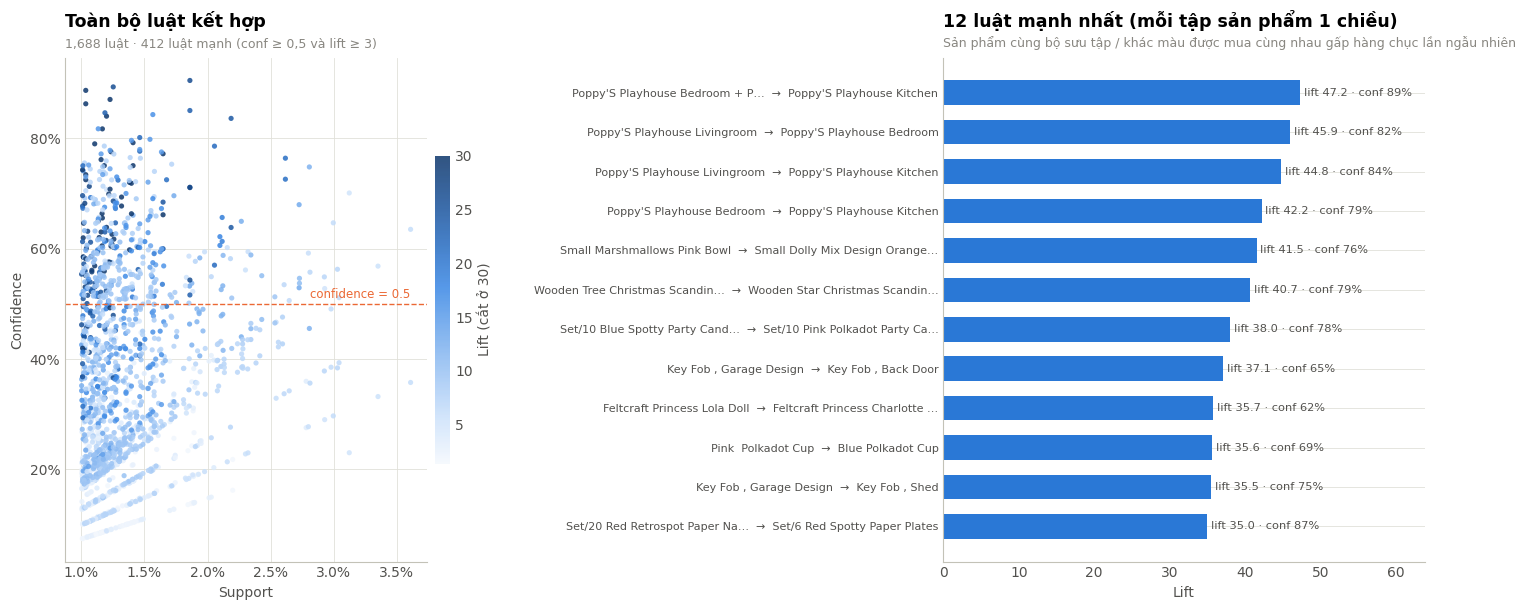

In [50]:
# MỤC ĐÍCH: Trực quan hóa các luật kết hợp nổi bật theo support, confidence và lift.

# Trực quan: (a) support × confidence tô màu theo lift, (b) 12 luật mạnh nhất xếp theo lift
fig, axes = plt.subplots(1, 2, figsize=(14.5, 6.2), gridspec_kw={"width_ratios": [1, 1.25]})
ax = axes[0]
sc = ax.scatter(rules.Support, rules.Confidence, c=rules.Lift.clip(upper=30), cmap=CMAP_SEQ, s=14, alpha=0.85,
                edgecolor="none")
ax.axhline(MIN_CONF, color=C["orange"], lw=1, ls="--")
ax.text(rules.Support.max(), MIN_CONF + 0.01, f"confidence = {MIN_CONF}", color=C["orange"], fontsize=8.5, ha="right")
ax.xaxis.set_major_formatter(mt.PercentFormatter(1, decimals=1)); ax.yaxis.set_major_formatter(PCT)
ax.set_xlabel("Support"); ax.set_ylabel("Confidence")
cb = fig.colorbar(sc, ax=ax, fraction=0.04, pad=0.02); cb.outline.set_visible(False); cb.set_label("Lift (cắt ở 30)", color=INK2)
ax.set_title("Toàn bộ luật kết hợp"); subtitle(ax, f"{len(rules):,} luật · {len(strong):,} luật mạnh (conf ≥ 0,5 và lift ≥ 3)")

ax = axes[1]
tr = top_rules.head(12).iloc[::-1]
lab_r = [f"{short(a_, 30)}  →  {short(c_, 30)}" for a_, c_ in zip(tr.Antecedent, tr.Consequent)]
ax.barh(lab_r, tr.Lift, color=C["blue"], height=0.62)
for i, (l_, c_) in enumerate(zip(tr.Lift, tr.Confidence)):
    ax.text(l_ + 0.5, i, f"lift {l_:.1f} · conf {c_:.0%}", va="center", fontsize=8.2, color=INK2)
ax.set_xlim(0, tr.Lift.max() * 1.35); clean_axis(ax, "y"); ax.tick_params(axis="y", labelsize=8)
ax.set_xlabel("Lift")
ax.set_title("12 luật mạnh nhất (mỗi tập sản phẩm 1 chiều)")
subtitle(ax, "Sản phẩm cùng bộ sưu tập / khác màu được mua cùng nhau gấp hàng chục lần ngẫu nhiên")
fig.tight_layout(w_pad=3)
save_fig(fig, "fig20_association_rules")

In [51]:
# MỤC ĐÍCH: Xác định mốc thời gian, cửa sổ quan sát và cửa sổ dự đoán để tránh rò rỉ dữ liệu.

# ============================================================
# 3.21 Tạo tập huấn luyện và tập kiểm tra theo 2 mốc thời gian
# ============================================================
HORIZON = pd.Timedelta(days=90)
CUT_TRAIN, CUT_TEST = pd.Timestamp("2011-06-10"), pd.Timestamp("2011-09-10")
TOP_COUNTRIES = ["United Kingdom", "Germany", "France", "Ireland"]
cancels_id = cancels.dropna(subset=["Customer ID"])


def build_dataset(cutoff):
    """Đặc trưng trước cutoff + nhãn mua lại trong 90 ngày sau cutoff."""
    X = customer_features(customers_tx, cutoff, cancels_id)
    # Đặc trưng xu hướng gần đây: doanh thu và số hoá đơn trong 90 ngày cuối trước mốc
    recent = customers_tx[(customers_tx.InvoiceDate < cutoff) & (customers_tx.InvoiceDate >= cutoff - HORIZON)]
    X["Rev_Last90"] = recent.groupby("Customer ID").Revenue.sum().reindex(X.index).fillna(0)
    X["Freq_Last90"] = recent.groupby("Customer ID").Invoice.nunique().reindex(X.index).fillna(0)
    # Gộp quốc gia hiếm thành 'Other' trước khi one-hot (giải trình ở 2.15)
    X["CountryGroup"] = X.Country.where(X.Country.isin(TOP_COUNTRIES), "Other")
    future = customers_tx[(customers_tx.InvoiceDate >= cutoff) & (customers_tx.InvoiceDate < cutoff + HORIZON)]
    y = X.index.isin(future["Customer ID"].unique()).astype(int)
    return X.drop(columns=["Country"]), pd.Series(y, index=X.index, name="Repurchase")


X_tr, y_tr = build_dataset(CUT_TRAIN)
X_te, y_te = build_dataset(CUT_TEST)
print(f"Train: {len(X_tr):,} khách | tỷ lệ mua lại {y_tr.mean():.1%}")
print(f"Test : {len(X_te):,} khách | tỷ lệ mua lại {y_te.mean():.1%}")
FACTS["clf_data"] = dict(n_train=len(X_tr), n_test=len(X_te), pos_train=float(y_tr.mean()), pos_test=float(y_te.mean()))
X_tr.head()

Train: 4,944 khách | tỷ lệ mua lại 32.0%
Test : 5,256 khách | tỷ lệ mua lại 43.5%


,Recency,Frequency,Monetary,Tenure,AvgOrderValue,AvgItemsPerOrder,UniqueProducts,ActiveMonths,AvgDaysBetween,CancelRate,Rev_Last90,Freq_Last90,CountryGroup
Customer ID,,,,,,,,,,,,,
12346,346,2,169.36,464,84.68,12.00,24,2,118.00,0.333,0.000,0.000,United Kingdom
12347,0,5,"2,817.48",221,563.50,28.40,101,5,54.75,0.000,"1,018.77",2.000,Other
12348,65,4,"1,388.40",255,347.10,10.00,24,4,63.00,0.000,327.00,1.000,Other
12349,224,2,"2,221.14",406,"1,110.57",50.00,89,2,181.00,0.333,0.000,0.000,Other
12350,127,1,294.40,127,294.40,16.00,16,1,127.00,0.000,0.000,0.000,Other


In [52]:
# MỤC ĐÍCH: Tạo tập đặc trưng và nhãn mua lại theo thiết kế kiểm định ngoài thời gian.

# ============================================================
# 3.22 Tiền xử lý theo loại mô hình
#   - Biến số lệch phải: log1p (CancelRate đã trong [0,1] nên giữ nguyên)
#   - Logistic Regression: + StandardScaler;  mô hình cây: không cần chuẩn hoá
#   - CountryGroup: One-hot (biến định danh, 5 nhóm)
# ============================================================
NUM = [c for c in X_tr.columns if c not in ("CountryGroup",)]
LOG_COLS = [c for c in NUM if c != "CancelRate"]


def log_transform(X):
    X = X.copy()
    X[LOG_COLS] = np.log1p(X[LOG_COLS].clip(lower=0))
    return X


Xtr_l, Xte_l = log_transform(X_tr), log_transform(X_te)
ohe = dict(handle_unknown="ignore")
pre_scaled = ColumnTransformer([("num", StandardScaler(), NUM), ("cat", OneHotEncoder(**ohe), ["CountryGroup"])])
pre_tree = ColumnTransformer([("num", "passthrough", NUM), ("cat", OneHotEncoder(**ohe), ["CountryGroup"])])

models = {
    "Logistic Regression": Pipeline([("pre", pre_scaled),
                                     ("clf", LogisticRegression(max_iter=2000, class_weight="balanced", C=1.0))]),
    "Random Forest": Pipeline([("pre", pre_tree),
                               ("clf", RandomForestClassifier(n_estimators=400, min_samples_leaf=10, class_weight="balanced",
                                                              n_jobs=-1, random_state=RANDOM_STATE))]),
    "Gradient Boosting": Pipeline([("pre", pre_tree),
                                   ("clf", HistGradientBoostingClassifier(learning_rate=0.05, max_iter=300, max_leaf_nodes=15,
                                                                          l2_regularization=1.0, class_weight="balanced",
                                                                          random_state=RANDOM_STATE))]),
}

In [53]:
# MỤC ĐÍCH: So sánh mô hình bằng kiểm định chéo phân tầng 5-fold trên tập huấn luyện.

# ============================================================
# 3.23 Kiểm định chéo 5-fold trên tập huấn luyện (ROC-AUC) để so sánh mô hình
# ============================================================
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_rows = []
for name, model in models.items():
    s = cross_val_score(model, Xtr_l, y_tr, cv=cv, scoring="roc_auc", n_jobs=-1)
    cv_rows.append({"Mô hình": name, "CV ROC-AUC (TB)": s.mean(), "CV ROC-AUC (độ lệch chuẩn)": s.std()})
cv_tbl = pd.DataFrame(cv_rows).set_index("Mô hình")
cv_tbl

,CV ROC-AUC (TB),CV ROC-AUC (độ lệch chuẩn)
Mô hình,,
Logistic Regression,0.823,0.011
Random Forest,0.824,0.010
Gradient Boosting,0.816,0.010


In [54]:
# MỤC ĐÍCH: Huấn luyện mô hình và đánh giá hiệu quả trên tập kiểm tra nằm ở giai đoạn thời gian sau.

# ============================================================
# 3.24 Huấn luyện trên toàn bộ tập train, đánh giá trên tập test ngoài thời gian
# Baseline: quy tắc nghiệp vụ "đã mua trong 90 ngày gần nhất thì sẽ mua lại"
# ============================================================
eval_rows, probas = [], {}
base_pred = (X_te.Freq_Last90 > 0).astype(int)
eval_rows.append({"Mô hình": "Baseline (mua trong 90 ngày qua)", "ROC-AUC": roc_auc_score(y_te, X_te.Freq_Last90),
                  "PR-AUC": average_precision_score(y_te, X_te.Freq_Last90), "Accuracy": accuracy_score(y_te, base_pred),
                  "Precision": precision_score(y_te, base_pred), "Recall": recall_score(y_te, base_pred),
                  "F1": f1_score(y_te, base_pred)})
for name, model in models.items():
    model.fit(Xtr_l, y_tr)
    p = model.predict_proba(Xte_l)[:, 1]; probas[name] = p
    pred = (p >= 0.5).astype(int)
    eval_rows.append({"Mô hình": name, "ROC-AUC": roc_auc_score(y_te, p), "PR-AUC": average_precision_score(y_te, p),
                      "Accuracy": accuracy_score(y_te, pred), "Precision": precision_score(y_te, pred),
                      "Recall": recall_score(y_te, pred), "F1": f1_score(y_te, pred)})
eval_tbl = pd.DataFrame(eval_rows).set_index("Mô hình").join(cv_tbl)
eval_tbl.to_csv(OUT_DIR / "classification_results.csv")
BEST = eval_tbl.drop(index="Baseline (mua trong 90 ngày qua)")["ROC-AUC"].idxmax()
FACTS["clf_results"] = eval_tbl.round(4).to_dict(orient="index"); FACTS["clf_best"] = BEST
print("Mô hình tốt nhất theo ROC-AUC trên tập test:", BEST)
eval_tbl

Mô hình tốt nhất theo ROC-AUC trên tập test: Logistic Regression


,ROC-AUC,PR-AUC,Accuracy,Precision,Recall,F1,CV ROC-AUC (TB),CV ROC-AUC (độ lệch chuẩn)
Mô hình,,,,,,,,
Baseline (mua trong 90 ngày qua),0.706,0.641,0.702,0.690,0.574,0.627,NaN,NaN
Logistic Regression,0.794,0.768,0.730,0.716,0.628,0.669,0.823,0.011
Random Forest,0.793,0.771,0.734,0.764,0.562,0.647,0.824,0.010
Gradient Boosting,0.786,0.766,0.732,0.755,0.568,0.648,0.816,0.010


Kiểm tra ma trận nhầm lẫn: 5,256 = số quan sát test 5,256


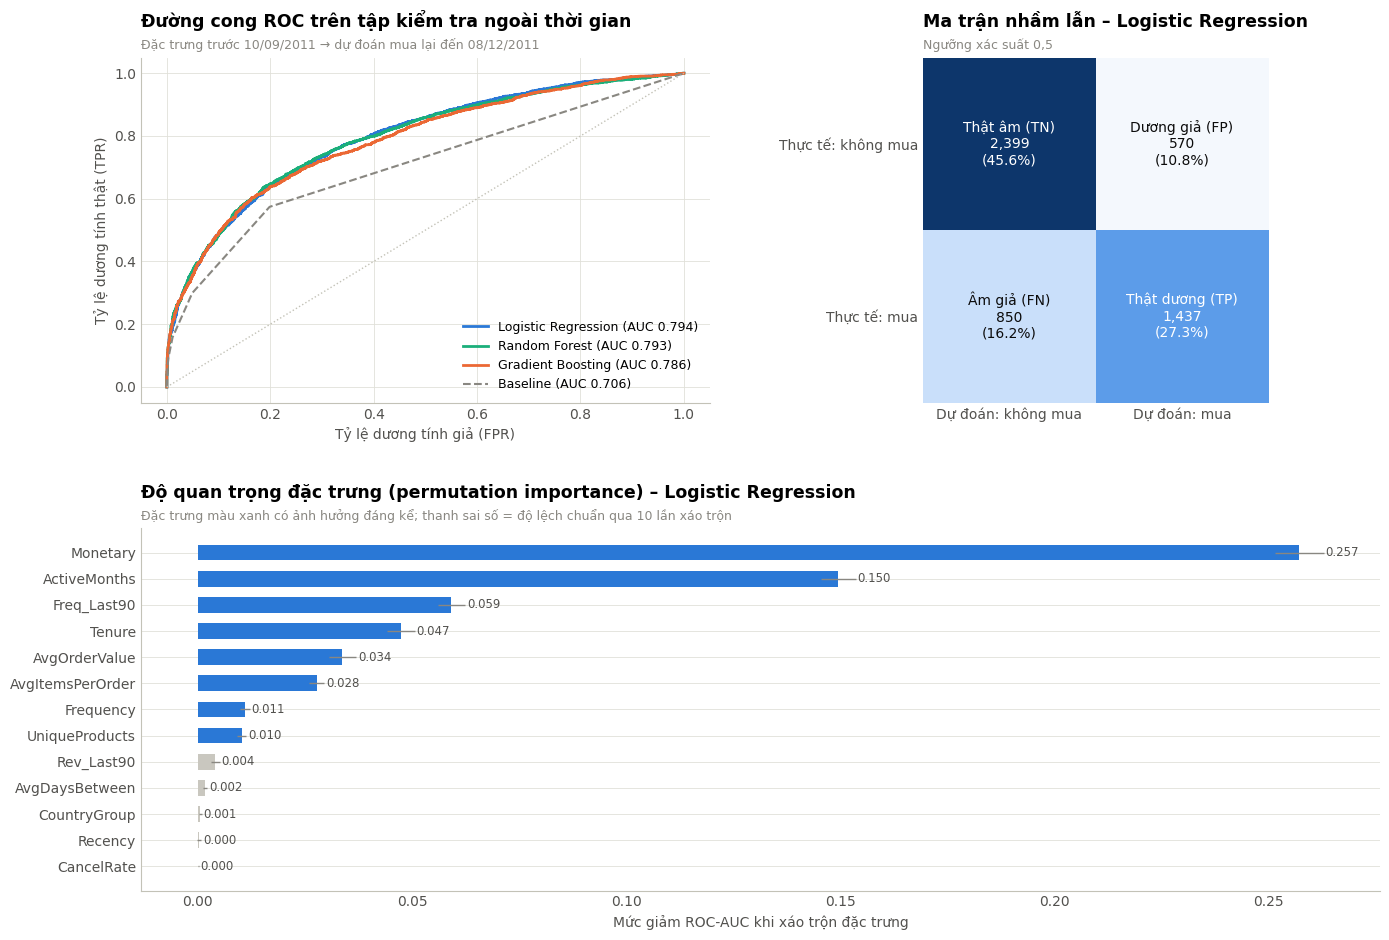

In [55]:
# MỤC ĐÍCH: Vẽ ROC, ma trận nhầm lẫn và permutation importance của mô hình tốt nhất.

# Trực quan: ROC, ma trận nhầm lẫn, độ quan trọng đặc trưng (permutation importance) của mô hình tốt nhất
fig = plt.figure(figsize=(14, 9.5))
gs = fig.add_gridspec(2, 2, height_ratios=[1, 1.05])
ax = fig.add_subplot(gs[0, 0])
for (name, p), colr in zip(probas.items(), [C["blue"], C["aqua"], C["orange"]]):
    fpr, tpr, _ = roc_curve(y_te, p)
    ax.plot(fpr, tpr, color=colr, lw=2, label=f"{name} (AUC {roc_auc_score(y_te, p):.3f})")
fpr, tpr, _ = roc_curve(y_te, X_te.Freq_Last90)
ax.plot(fpr, tpr, color=MUTED, lw=1.5, ls="--", label=f"Baseline (AUC {roc_auc_score(y_te, X_te.Freq_Last90):.3f})")
ax.plot([0, 1], [0, 1], color=AXIS, lw=1, ls=":")
ax.set_xlabel("Tỷ lệ dương tính giả (FPR)"); ax.set_ylabel("Tỷ lệ dương tính thật (TPR)"); ax.legend(loc="lower right")
ax.set_title("Đường cong ROC trên tập kiểm tra ngoài thời gian"); subtitle(ax, "Đặc trưng trước 10/09/2011 → dự đoán mua lại đến 08/12/2011")

ax = fig.add_subplot(gs[0, 1])
cm = confusion_matrix(y_te, (probas[BEST] >= 0.5).astype(int), labels=[0, 1])
assert int(cm.sum()) == len(y_te), "Tổng ma trận nhầm lẫn phải bằng số quan sát tập test"
print(f"Kiểm tra ma trận nhầm lẫn: {cm.sum():,} = số quan sát test {len(y_te):,}")
ax.imshow(cm, cmap=CMAP_SEQ)
lab_cm = [["Thật âm (TN)", "Dương giả (FP)"], ["Âm giả (FN)", "Thật dương (TP)"]]
for i in range(2):
    for j in range(2):
        ax.text(j, i, f"{lab_cm[i][j]}\n{cm[i, j]:,}\n({cm[i, j]/cm.sum():.1%})", ha="center", va="center", fontsize=10,
                color="white" if cm[i, j] > cm.max() * 0.5 else INK)
ax.set_xticks([0, 1], ["Dự đoán: không mua", "Dự đoán: mua"]); ax.set_yticks([0, 1], ["Thực tế: không mua", "Thực tế: mua"])
ax.grid(False); [s.set_visible(False) for s in ax.spines.values()]
ax.set_title(f"Ma trận nhầm lẫn – {BEST}"); subtitle(ax, "Ngưỡng xác suất 0,5")

ax = fig.add_subplot(gs[1, :])
pi = permutation_importance(models[BEST], Xte_l, y_te, scoring="roc_auc", n_repeats=10, random_state=RANDOM_STATE, n_jobs=-1)
imp = pd.Series(pi.importances_mean, index=Xte_l.columns).sort_values()
imp_sd = pd.Series(pi.importances_std, index=Xte_l.columns).loc[imp.index]
ax.barh(imp.index, imp.values, xerr=imp_sd.values, color=[C["blue"] if v > 0.005 else NEUTRAL for v in imp.values],
        height=0.6, error_kw=dict(ecolor=MUTED, lw=1))
for i, v in enumerate(imp.values):
    ax.text(max(v, 0) + imp_sd.iloc[i] + 0.0004, i, f"{v:.3f}", va="center", fontsize=8.5, color=INK2)
clean_axis(ax, "y"); ax.set_xlabel("Mức giảm ROC-AUC khi xáo trộn đặc trưng")
ax.set_title(f"Độ quan trọng đặc trưng (permutation importance) – {BEST}")
subtitle(ax, "Đặc trưng màu xanh có ảnh hưởng đáng kể; thanh sai số = độ lệch chuẩn qua 10 lần xáo trộn")
fig.tight_layout(h_pad=3, w_pad=3)
save_fig(fig, "fig21_classification")
imp.to_csv(OUT_DIR / "feature_importance.csv")
FACTS["feature_importance"] = imp.sort_values(ascending=False).round(4).to_dict()
FACTS["cm_best"] = cm.tolist()

In [56]:
# MỤC ĐÍCH: Xếp hạng khách hàng theo xác suất mua lại và tính tỷ lệ khách mua được bắt trúng theo decile.

# ============================================================
# 3.25 Ứng dụng: xếp hạng khách theo xác suất mua lại – nhóm 20% cao nhất bắt được bao nhiêu khách sẽ mua?
# ============================================================
lift_tbl = pd.DataFrame({"p": probas[BEST], "y": y_te.values}).sort_values("p", ascending=False)
lift_tbl["decile"] = pd.qcut(np.arange(len(lift_tbl)), 10, labels=[f"D{i}" for i in range(1, 11)])
dec = lift_tbl.groupby("decile", observed=True).agg(Tỷ_lệ_mua_lại=("y", "mean"), Số_khách=("y", "size"))
dec["Lift so với TB"] = dec.Tỷ_lệ_mua_lại / y_te.mean()
dec["% khách mua lại tích luỹ"] = lift_tbl.groupby("decile", observed=True).y.sum().cumsum() / y_te.sum() * 100
FACTS["top20_capture"] = float(dec["% khách mua lại tích luỹ"].iloc[1]); FACTS["d1_rate"] = float(dec.Tỷ_lệ_mua_lại.iloc[0])
FACTS["d10_rate"] = float(dec.Tỷ_lệ_mua_lại.iloc[-1])
dec

,Tỷ_lệ_mua_lại,Số_khách,Lift so với TB,% khách mua lại tích luỹ
decile,,,,
D1,0.914,526,2.102,21.03
D2,0.757,526,1.739,38.43
D3,0.621,525,1.427,52.69
D4,0.534,526,1.228,64.98
D5,0.410,525,0.941,74.38
D6,0.346,526,0.795,82.33
D7,0.278,525,0.639,88.72
D8,0.213,526,0.489,93.62
D9,0.183,525,0.420,97.81


In [57]:
# MỤC ĐÍCH: Tổng hợp các chỉ số then chốt và xuất kết quả để đối chiếu với báo cáo PDF.

# ============================================================
# 4.1 Tóm tắt các con số then chốt và xuất ra file JSON
# ============================================================
summary = pd.Series({
    "Dòng dữ liệu thô → sạch": f"{FACTS['raw_rows']:,} → {FACTS['clean_rows']:,}",
    "Tổng doanh thu hợp lệ": f"£{FACTS['clean_revenue']:,.0f}",
    "Tăng trưởng doanh thu T1–T11 (2011 vs 2010)": f"{FACTS['yoy_growth']:+.1%}",
    "Tỷ trọng doanh thu T9–T11": f"{FACTS['share_sep_nov']:.1%}",
    "Tỷ trọng doanh thu Vương quốc Anh": f"{FACTS['uk_share']:.1%}",
    "20% khách hàng tạo ra": f"{FACTS['customers_top20_share']:.1%} doanh thu",
    "Số luật kết hợp mạnh": f"{FACTS['rules']['n_strong']:,}",
    "Mô hình dự đoán tốt nhất": f"{BEST} – ROC-AUC {FACTS['clf_results'][BEST]['ROC-AUC']:.3f}",
}).to_frame("Giá trị")


def _to_py(o):
    if isinstance(o, (np.integer,)): return int(o)
    if isinstance(o, (np.floating,)): return float(o)
    if isinstance(o, (pd.Timestamp, pd.Period)): return str(o)
    return str(o)


with open(OUT_DIR / "key_facts.json", "w", encoding="utf-8") as fh:
    json.dump(FACTS, fh, ensure_ascii=False, indent=2, default=_to_py)
summary

,Giá trị
Dòng dữ liệu thô → sạch,"1,067,371 → 1,003,321"
Tổng doanh thu hợp lệ,"£19,288,350"
Tăng trưởng doanh thu T1–T11 (2011 vs 2010),+1.5%
Tỷ trọng doanh thu T9–T11,36.9%
Tỷ trọng doanh thu Vương quốc Anh,85.3%
20% khách hàng tạo ra,76.7% doanh thu
Số luật kết hợp mạnh,412
Mô hình dự đoán tốt nhất,Logistic Regression – ROC-AUC 0.794
